# Which Steam Hits Keep Their Players?
### Predicting a game's staying power from information available on launch day

**Course:** INSY 674, Enterprise Data Science (McGill, Fall 2026)
**Team:** TODO: names

**How to run:** open in Google Colab (or Jupyter) and use *Run all*. The first code cell downloads the two data files from Hugging Face if they aren't already in the same folder: `steam_games.parquet` (about 190 MB) and `steam_games.csv` (about 400 MB). A full run took about 5 minutes on a 2-core machine (similar to Colab's free tier), plus download time.

**Notebook structure (follows the Géron checklist, Appendix B):**
1. Frame the problem and look at the big picture
2. Get the data, choose the games, define the target, split off the test set
3. Explore the data
4. Prepare the data (leakage audit, feature engineering, pipeline)
5. Shortlist promising models: measure and compare
6. Fine-tune the system, ensembles, final test-set evaluation and robustness checks
7. Conclusion, assumptions and limitations

Code adapted from Aurélien Géron's Chapter 2 notebook says "(adapted from Géron)" in its comments: https://github.com/ageron/handson-ml3/blob/main/02_end_to_end_machine_learning_project.ipynb

> **Template note:** sections marked **TODO** are choices or wording for the team to review. The takeaways under each result were written from our full run; re-check them if you change the settings.

In [1]:
# Imports used throughout the notebook
import os
import re
import time
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

# ---------------- Project settings (TODO: the team can change these) ----------------
RANDOM_STATE = 42

WINDOW_START, WINDOW_END = 2019, 2023  # release years we study (every game is 2.5+ years old)
HIT_THRESHOLD = 500                    # total reviews needed to count as a "hit"
LASTING_QUANTILE = 0.75                # "lasting" = top 25% of current players per review, within each release year

TEST_SIZE = 0.2   # share of games held out as the final test set
CV_FOLDS = 5      # N in N-fold cross-validation
N_ITER = 25       # random-search iterations per model

# Data files (FronkonGames Steam Games Dataset on Hugging Face)
# Pinned to the dataset version we used (Hugging Face commit of 2 Oct 2026), so results are reproducible
BASE_URL = "https://huggingface.co/datasets/FronkonGames/steam-games-dataset/resolve/ba4e26785af33bee500e96597068c6e77f4edea9/"
FILES = {"steam_games.parquet": BASE_URL + "data/train-00000-of-00001.parquet",  # main data
         "steam_games.csv": BASE_URL + "games.csv"}                              # adds Discount and Tags

for path, url in FILES.items():
    if not os.path.exists(path):
        import urllib.request
        print("Downloading", path, "...")
        urllib.request.urlretrieve(url, path)
print("Data files ready:", list(FILES))

Data files ready: ['steam_games.parquet', 'steam_games.csv']


## 1. Frame the Problem and Look at the Big Picture

**Objective (business).** Getting players to buy a game is only half the story. For many studios the real money, and the decision about whether to keep investing, depends on whether players **stay**: post-launch updates, DLC, in-game purchases, word of mouth and sequels all rely on an active player base. Most games, even successful ones, lose almost all their players within months. A few are still being played years later.

**Our question:** *among Steam games that found an audience, which characteristics known on launch day predict that the game will still have an active player base years later?*

**Who would use it and how.**
- *Developers in the design phase* could see which design choices (multiplayer, co-op, mod support, genre, achievements, price) go with long-lasting games, and weigh them against their cost.
- *Publishers* deciding which recent hits to fund updates, DLC or sequels for could use the predicted probability as one input, alongside their own sales data.
- The output is a probability plus the main drivers. It describes what long-lasting games have in common; it doesn't prove that adding a feature will make a game last.

**Current solutions and workarounds.** Studios mostly look at the player-count history of comparable games on sites like SteamDB, and rely on experience. That shows what happened to *other* games after the fact, but it doesn't combine many factors or quantify how much each one matters. TODO: add a source if the team wants to cite one.

**How we frame the ML problem.**
- **Supervised learning:** every game already has an observed outcome (its current player count), so we learn from labelled examples.
- **Binary classification:** *lasting (1) vs. not lasting (0)*. Current player counts are a single-day snapshot and very noisy, so predicting "is this game in the top group" is more robust than predicting the exact number.
- **Batch (offline) learning:** we train once on a fixed snapshot of the Steam store.

**How we measure staying power.** The dataset has `peak_ccu`: the peak number of people playing the game at the same time on the day before the data was collected (around September 2026). Two things distort a raw player count:
- **Size:** bigger hits naturally have more players at any time.
- **Age:** newer games have had less time to lose players.

So we compare each game with **what is typical for a game of the same size (total reviews) and release year**, and call a game **lasting** if it has *more current players than expected*, in the **top 25%** of its release year (Section 2.3).

**Performance measure.**
- About 25% of games are "lasting" by construction, so a random guess scores a **PR-AUC of about 0.25**.
- **Main metric: PR-AUC (average precision)**, which measures how well the model ranks lasting games above the rest.
- We also report **ROC-AUC**, plus **F1, precision and recall** at a chosen threshold, which are easier to explain.

**Is the measure aligned with the objective?** Yes. A publisher using the tool wants the games it flags as "likely to last" to really last (precision), without missing too many of them (recall). PR-AUC summarises that trade-off across all thresholds.

## 2. Get the Data, Choose the Games, Define the Target

**Dataset:** FronkonGames, *Steam Games Dataset*, Hugging Face (also on Kaggle). https://huggingface.co/datasets/FronkonGames/steam-games-dataset. It's one row per game scraped from the Steam store and SteamSpy, covering games released up to September 2026. TODO: write down the date you downloaded it.

We use two versions of it:
- **The parquet file (main data):** 41 columns with clean list columns.
- **The CSV file (two extra columns):** `Discount` (the % discount on the snapshot day) and `Tags` (player-applied tags). The CSV has a known header bug: the column names "Discount" and "DLC count" are merged into one, so we supply corrected names when reading it.

In [2]:
# Main data
games_all = pd.read_parquet("steam_games.parquet")
print("Parquet rows, columns:", games_all.shape)

# Extra columns from the CSV (fix the merged "DiscountDLC count" header first)
header = pd.read_csv("steam_games.csv", nrows=0).columns.tolist()
fixed_header = header[:7] + ["Discount", "DLC count"] + header[8:]
extras = pd.read_csv("steam_games.csv", header=0, names=fixed_header, index_col=False,
                     usecols=["AppID", "Discount", "Tags"], low_memory=False)
extras["AppID"] = extras["AppID"].astype(str)
print("CSV rows:", len(extras))

games_all = games_all.merge(extras.rename(columns={"AppID": "appID", "Discount": "discount", "Tags": "tags_csv"}),
                            on="appID", how="left")
print("Games without CSV extras:", games_all["discount"].isna().sum())
games_all.head(3)

Parquet rows, columns: (124146, 41)


CSV rows: 125855
Games without CSV extras: 0


,appID,name,release_date,estimated_owners,peak_ccu,required_age,price,dlc_count,detailed_description,short_description,supported_languages,full_audio_languages,reviews,header_image,website,support_url,support_email,windows,mac,linux,metacritic_score,metacritic_url,user_score,positive,negative,score_rank,achievements,recommendations,notes,average_playtime_forever,average_playtime_2weeks,median_playtime_forever,median_playtime_2weeks,developers,publishers,categories,genres,tags,screenshots,movies,packages,discount,tags_csv
0,2539430,Black Dragon Mage Playtest,"Aug 1, 2023",0 - 0,0,0,0.00,0,,,[],[],,https://shared.akamai.steamstatic.com/store_it...,,,,True,False,False,0,,0,0,0,,0,0,,0,0,0,0,[],[],[],[],[],[https://shared.akamai.steamstatic.com/store_i...,[],[],0,NaN
1,496350,Supipara - Chapter 1 Spring Has Come!,"Jul 29, 2016",0 - 20000,0,0,5.24,0,"Springtime, April: when the cherry trees come ...","Spring has come, and our protagonist, Yukinari...",[English],[],,https://shared.akamai.steamstatic.com/store_it...,http://mangagamer.org/supipara,http://mangagamer.com,support@mangagamer.com,True,False,False,0,,0,252,3,,0,231,,8,0,8,0,[minori],[MangaGamer],"[Single-player, Steam Trading Cards, Steam Clo...",[Adventure],[],[https://shared.akamai.steamstatic.com/store_i...,[],"[{""title"": ""Buy Supipara - Chapter 1 Spring Ha...",65,"Adventure,Visual Novel,Anime,Cute"
2,1034400,Mystery Solitaire The Black Raven,"May 6, 2019",0 - 20000,0,0,4.99,0,"Immerse yourself in the most beloved, mystical...",Discover an entrancing and spectacular world!,"[English, French, German, Russian]",[],,https://shared.akamai.steamstatic.com/store_it...,https://www.facebook.com/8FloorGames/,https://www.facebook.com/8FloorGames,support@8floor.net,True,True,False,0,,0,21,3,,0,0,,0,0,0,0,[Somer Games],[8floor],"[Single-player, Family Sharing]",[Casual],[],[https://shared.akamai.steamstatic.com/store_i...,[],"[{""title"": ""Buy Mystery Solitaire The Black Ra...",0,"Casual,Card Game,Solitaire,Puzzle,Hidden Objec..."


In [3]:
# Dates, review totals and the staying-power measure
games_all["release_dt"] = pd.to_datetime(games_all["release_date"], format="mixed", errors="coerce")
games_all["release_year"] = games_all["release_dt"].dt.year
games_all["total_reviews"] = games_all["positive"] + games_all["negative"]

# Current players per 1,000 reviews: how much of its audience a game has kept
games_all["players_per_1k"] = 1000 * games_all["peak_ccu"] / games_all["total_reviews"].replace(0, np.nan)

print("Unparseable release dates:", games_all["release_dt"].isna().sum())
print("Latest release date in the data:", games_all["release_dt"].max().date())

Unparseable release dates: 0
Latest release date in the data: 2026-09-08


### 2.1 Choosing which games to study

| Filter | Why |
|---|---|
| Released 2019–2023 | Every game has been on sale for at least about 2.5 years, so "still played" means something. Older games come from a smaller, different Steam |
| Has a description, a screenshot, a developer and a genre; not a playtest | Removes placeholder and empty store pages |
| **At least 500 reviews (a "hit")** | Staying power only makes sense for games that had an audience to keep. Among all games, 84% had zero players on the snapshot day, so the question would collapse into "was it ever popular?" |
| Not software | Titles with only non-game genres (Utilities, Video Production, ...) aren't games |
| Not an idle or clicker game | People leave idle games running in the background, which inflates their player counts (about 3× the typical players per review). We identify them with the CSV's player tags "Idler", "Clicker" and "Incremental" |

Tags are applied by players after launch, so we use them **only to choose which games to study**, never as model features.

In [4]:
def n_items(value):
    # Number of items in a list-like cell (lists come in as numpy arrays from parquet)
    if value is None or (isinstance(value, float) and np.isnan(value)):
        return 0
    return len(value)

GAME_GENRES = {"Action", "Adventure", "Casual", "Indie", "RPG", "Simulation", "Strategy", "Sports",
               "Racing", "Massively Multiplayer", "Free To Play", "Early Access", "Violent", "Gore"}
IDLE_TAGS = {"Idler", "Clicker", "Incremental"}

steps = [("all games", len(games_all))]
games = games_all[games_all["release_year"].between(WINDOW_START, WINDOW_END)].copy()
steps.append((f"released {WINDOW_START}-{WINDOW_END}", len(games)))

basic_ok = ((games["short_description"].fillna("").str.strip().str.len() > 0)
            & (games["screenshots"].map(n_items) > 0)
            & (games["developers"].map(n_items) > 0)
            & (games["genres"].map(n_items) > 0)
            & ~games["name"].fillna("").str.contains("playtest", case=False))
games = games[basic_ok]
steps.append(("has description, screenshot, developer, genre; not a playtest", len(games)))

games = games[games["total_reviews"] >= HIT_THRESHOLD]
steps.append((f"a hit: {HIT_THRESHOLD}+ reviews", len(games)))

games = games[games["genres"].map(lambda g: len(set(g) & GAME_GENRES) > 0)]
steps.append(("is a game (not only software genres)", len(games)))

is_idle = games["tags_csv"].fillna("").str.split(",").map(lambda t: len(set(t) & IDLE_TAGS) > 0)
games = games[~is_idle]
steps.append(("not an idle / clicker game", len(games)))

pd.DataFrame(steps, columns=["filter", "games remaining"])

,filter,games remaining
0,all games,124146
1,released 2019-2023,53994
2,"has description, screenshot, developer, genre;...",50865
3,a hit: 500+ reviews,4261
4,is a game (not only software genres),4242
5,not an idle / clicker game,4117


### 2.2 Train/test split

Like Géron, we split off the test set **before** exploring, so nothing we see in it can influence our choices. The split is **stratified by release year**, so every year is represented equally in both sets. The test set is only used once, at the very end (Section 6.4).

In [5]:
# Stratified 80/20 split by release year (adapted from Géron)
from sklearn.model_selection import train_test_split

train_set, test_set = train_test_split(games, test_size=TEST_SIZE, stratify=games["release_year"],
                                       random_state=RANDOM_STATE)
train_set, test_set = train_set.copy(), test_set.copy()
print("Training games:", len(train_set), "| test games:", len(test_set))

Training games: 3293 | test games: 824


### 2.3 Defining the target: "lasting"

A raw player count mostly measures how *big* a game was and how *new* it is. Our first idea, dividing players by reviews, wasn't enough: bigger hits still kept a much larger share of their players (see Plot 5). So we define staying power as **more players than expected for a game of the same size and age**:

1. On the training set, fit a simple linear regression: `log(current players + 1)` explained by `log(total reviews)` and the release year. Its prediction is the **expected** number of players for a game of that size and year.
2. A game's **residual** is how far above or below expectation it is (positive = more players than expected).
3. A game is **lasting** if its residual is in the **top 25% of games released in the same year**.

> In plain words: *a lasting game has more people still playing it than almost every other game of its size and age.*

The regression and the cutoffs are fitted **on the training set only** and then applied to both sets, so the test set doesn't influence the definition of the target. Total reviews are used *only* to define the target, never as a model feature.

In [6]:
from sklearn.linear_model import LinearRegression

YEARS = list(range(WINDOW_START, WINDOW_END + 1))

def size_and_year(df):
    # Inputs of the "expected players" regression: log10(total reviews) + one column per release year
    out = pd.DataFrame({"log_reviews": np.log10(df["total_reviews"])}, index=df.index)
    for y in YEARS[1:]:
        out[f"year_{y}"] = (df["release_year"] == y).astype(float)
    return out

log_players = lambda df: np.log10(df["peak_ccu"] + 1)

expected_model = LinearRegression().fit(size_and_year(train_set), log_players(train_set))
for df in (train_set, test_set):
    df["residual"] = log_players(df) - expected_model.predict(size_and_year(df))
    df["expected_players"] = (10 ** expected_model.predict(size_and_year(df)) - 1).round(1)

cutoffs = train_set.groupby("release_year")["residual"].quantile(LASTING_QUANTILE)
for df in (train_set, test_set):
    df["lasting"] = (df["residual"] > df["release_year"].map(cutoffs)).astype(int)

slope = expected_model.coef_[0]
print(f"Slope on log(reviews): {slope:.2f} -> a game with 10x more reviews has about {10**slope:.0f}x more current players")
print(f"R² of the expected-players regression (train): {expected_model.score(size_and_year(train_set), log_players(train_set)):.2f}")
print("Share lasting -> train:", round(train_set["lasting"].mean(), 3), "| test:", round(test_set["lasting"].mean(), 3))

pd.DataFrame({
    "residual cutoff (log10 units)": cutoffs.round(2),
    "= this many times the expected players": (10 ** cutoffs).round(2),
    "% lasting (train)": (train_set.groupby("release_year")["lasting"].mean() * 100).round(1),
})

Slope on log(reviews): 1.23 -> a game with 10x more reviews has about 17x more current players
R² of the expected-players regression (train): 0.66
Share lasting -> train: 0.25 | test: 0.258


,residual cutoff (log10 units),= this many times the expected players,% lasting (train)
release_year,,,
2019,0.29,1.96,25.1
2020,0.31,2.03,25.0
2021,0.27,1.88,25.0
2022,0.31,2.02,25.0
2023,0.31,2.03,25.1


**Takeaway:**
- **Lasting means roughly double the expected players.** In every release year the cutoff works out to about **1.9–2.0× the expected number of players** for a game of that size and age, and exactly 25% of training games qualify.
- **Interesting finding along the way:** the slope of 1.23 means **bigger hits keep proportionally more of their players**. A game with 10× more reviews has about 17× more people playing today, not 10×. That's why dividing by reviews wasn't enough.
- **The expected-players regression explains about two-thirds of the variation** (R² 0.66). The remaining third, what size and age don't explain, is what our model tries to predict.

## 3. Explore the Data

We are going to be exploring a **copy of the training set only**.

### 3.1 Profile of every attribute

The function below shows us for each original column plus the two CSV extras, what kind of data it is (data type), the % of missingness (empty text and empty lists count as missing), the number of unique values, and for numeric columns the % of zeros, range and skewness. The written profile underneath adds noise, distribution and usefulness.

In [7]:
explore = train_set.copy()
profile_columns = list(games_all.columns[:41]) + ["discount", "tags_csv"]

def profile(df, columns):
    rows = []
    for col in columns:
        s = df[col]
        sample = s.dropna()
        first = sample.iloc[0] if len(sample) else None
        row = {"column": col}
        if isinstance(first, (list, np.ndarray)):
            row["kind"] = "list"
            empty = s.map(n_items) == 0
            row["avg items"] = round(s.map(n_items).mean(), 2)
            row["n unique"] = s.map(lambda v: "|".join(map(str, v)) if v is not None else "").nunique()
        elif pd.api.types.is_bool_dtype(s):
            row["kind"] = "bool"
            empty = s.isna()
            row["% true"] = round(s.mean() * 100, 1)
            row["n unique"] = s.nunique()
        elif pd.api.types.is_numeric_dtype(s):
            row["kind"] = "numeric"
            empty = s.isna()
            row["% zero"] = round((s == 0).mean() * 100, 1)
            row["min"], row["median"], row["max"] = s.min(), s.median(), s.max()
            row["skew"] = round(s.skew(), 1)
            row["n unique"] = s.nunique()
        else:
            row["kind"] = "text"
            empty = s.isna() | (s.astype(str).str.strip() == "")
            row["n unique"] = s.nunique()
        row["% missing/empty"] = round(empty.mean() * 100, 1)
        rows.append(row)
    cols = ["column", "kind", "% missing/empty", "n unique", "% zero", "% true",
            "avg items", "min", "median", "max", "skew"]
    return pd.DataFrame(rows).reindex(columns=cols)

profile_table = profile(explore, profile_columns)
profile_table

,column,kind,% missing/empty,n unique,% zero,% true,avg items,min,median,max,skew
0,appID,text,0.0,3293,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,name,text,0.0,3293,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,release_date,text,0.0,1217,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,estimated_owners,text,0.0,13,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,peak_ccu,numeric,0.0,521,12.5,NaN,NaN,0.0,8.00,124262.00,23.6
5,required_age,numeric,0.0,6,94.4,NaN,NaN,0.0,0.00,18.00,3.9
6,price,numeric,0.0,269,13.0,NaN,NaN,0.0,5.19,69.99,2.4
7,dlc_count,numeric,0.0,66,45.2,NaN,NaN,0.0,1.00,3703.00,49.8
8,detailed_description,text,0.2,3282,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,short_description,text,0.0,3280,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Table: Written attribute profile.** 

- **ID** = identifier (dropped) 
- **Feature** = known on launch day (used, mostly after engineering)
- **Target** = What we want to predict
- **Leakage** = measures that can only be known after launch or caused by the outcome (dropped) 
- **Filter** = used only to choose the games

| Attribute | Type | Missing / noise | Distribution | Usefulness / role |
|---|---|---|---|---|
| appID | text ID | none | unique | ID: used to join the two files |
| name | text | none | unique | Feature source: sequel flag from numbers in the title (noisy) |
| release_date | text date | none | 2019–2023 | Feature: year, month, weekday, also defines the year cohort for the target |
| estimated_owners | text ranges | very coarse ranges | mostly 20k–500k for hits | Leakage (outcome) |
| peak_ccu | int, unbounded | one day only, so very noisy (weekends, sales, updates) | extremely rightskewed, due to many 0s | **Target** (with total reviews) |
| required_age | int, 0–21 | mostly 0 | near-constant | Feature (weak) |
| price | float | **snapshot price: about 2/3 of these games were on sale that day** | rightskewed | Replaced by `regular_price` (price before discount) |
| discount (CSV) | int % | none | 0 for about a third, otherwise 10–90% | Used only to recover the regular price; a sale on one day is not a launch-day fact |
| dlc_count | int | mostly 0 | extremely skewed | Leakage: DLC is released *because* players stay |
| detailed_description, short_description | text | none | lengths right-skewed | Feature: description lengths |
| supported_languages, full_audio_languages | lists | few empty | right-skewed counts | Feature: counts (some languages may be added after launch) |
| reviews | text (press quotes) | mostly empty | n/a | Leakage (post-launch press) |
| header_image, website, support_url, support_email, metacritic_url, packages | text/URLs | some empty | n/a | ID (we keep only "has a website") |
| windows | bool | none | almost always true | Dropped (no information) |
| mac, linux | bool | none | minority true | Feature: platform reach |
| metacritic_score, user_score, score_rank | int/text | mostly 0/empty | skewed | Leakage (post-launch ratings) |
| positive, negative | int | none | extremely right-skewed | **Target** (total reviews is the denominator of our measure); also used to select hits |
| achievements | int | some 0s | right-skewed with extreme outliers | Feature |
| recommendations | int | few 0s | right-skewed | Leakage (outcome) |
| notes | text | mostly empty | n/a | Feature: "has content notes" (mature content) |
| average/median playtime (forever, 2 weeks) | int, minutes | 2-week values mostly 0 | extremely skewed | Leakage (measured from players after launch) |
| developers, publishers | lists | publishers rarely empty | very high cardinality | Feature: track record, self-published, main publisher |
| categories | list | none | Single-player dominant | Feature (minus leaky values, Section 4.1) |
| genres | list | none | Indie, Action, Adventure dominant | Feature |
| tags (parquet) / tags_csv | list / text | parquet empty; CSV filled | player-applied | Filter only (idle games); leakage as a feature |
| screenshots | list of URLs | none | median about 10 | Feature: count |
| movies | list | 100% empty in this version | n/a | Dropped (no data) |

### 3.2 Visualizing the data

A few quick glances at the columns included.

In [8]:
explore["regular_price"] = np.where(explore["discount"].between(1, 99),
                                    explore["price"] / (1 - explore["discount"] / 100), explore["price"])
explore["n_languages"] = explore["supported_languages"].map(n_items)
explore["n_screenshots"] = explore["screenshots"].map(n_items)
explore["is_free"] = (explore["price"] == 0).astype(int)
explore["log_reviews"] = np.log10(explore["total_reviews"])

#### Plot 1: Current players vs. size of the hit, and which games count as lasting

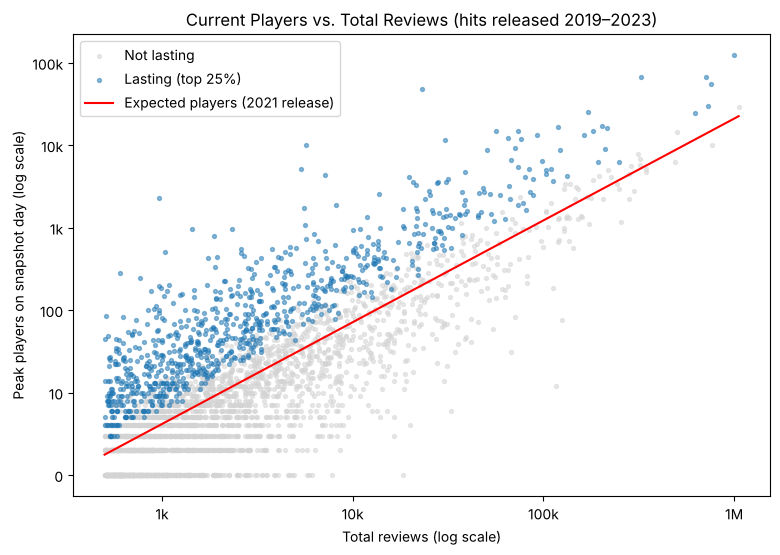

Hits with 0 players on the snapshot day: 12.5 %


In [9]:
plt.figure(figsize=(9, 6))
for value, color, label in [(0, "lightgray", "Not lasting"), (1, "tab:blue", "Lasting (top 25%)")]:
    part = explore[explore["lasting"] == value]
    plt.scatter(np.log10(part["total_reviews"]), np.log10(part["peak_ccu"] + 1), s=8, alpha=0.5,
                color=color, label=label)
grid = np.linspace(np.log10(HIT_THRESHOLD), explore["log_reviews"].max(), 50)
middle_year = pd.DataFrame({"total_reviews": 10 ** grid, "release_year": 2021})
plt.plot(grid, expected_model.predict(size_and_year(middle_year)), color="red",
         label="Expected players (2021 release)")
plt.xticks([3, 4, 5, 6], ["1k", "10k", "100k", "1M"])
plt.yticks([0, 1, 2, 3, 4, 5], ["0", "10", "100", "1k", "10k", "100k"])
plt.title("Current Players vs. Total Reviews (hits released 2019–2023)")
plt.xlabel("Total reviews (log scale)")
plt.ylabel("Peak players on snapshot day (log scale)")
plt.legend()
plt.show()

print("Hits with 0 players on the snapshot day:", round((explore["peak_ccu"] == 0).mean() * 100, 1), "%")

**Insight:**
- **Size:** current players rise steadily with total reviews (red line).
- **There's a wide spread around the line.** At the same size, some games have 10× the expected players and others have none. **12.5% of these hits had zero players** on the snapshot day.
- **Lasting games (blue) sit above the line at every size,** so our target picks out over performers among small and large hits alike.
- **The horizontal stripes at the bottom left** are small games with 0 to 2 players; with such small counts, one day's numbers are noisy which is a limitation to keep in mind.

#### Plot 2: Share of lasting games by genre

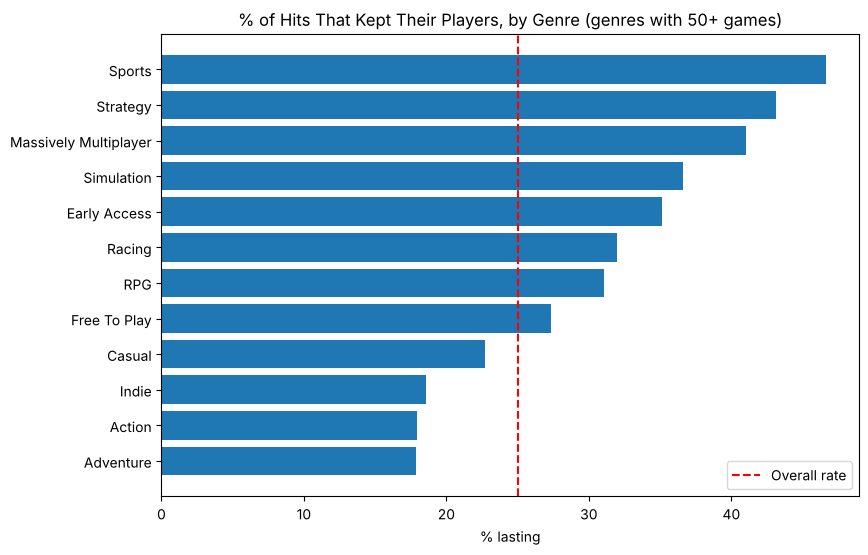

,mean,count
genres,,
Sports,0.466,148
Strategy,0.431,765
Massively Multiplayer,0.410,134
Simulation,0.366,965
Early Access,0.352,256
Racing,0.320,125
RPG,0.311,911
Free To Play,0.273,322
Casual,0.227,907


In [10]:
genre_stats = (explore[["genres", "lasting"]].explode("genres")
               .groupby("genres")["lasting"].agg(["mean", "count"])
               .query("count >= 50").sort_values("mean"))

plt.figure(figsize=(9, 6))
plt.barh(genre_stats.index, genre_stats["mean"] * 100)
plt.axvline(explore["lasting"].mean() * 100, color="red", linestyle="--", label="Overall rate")
plt.title("% of Hits That Kept Their Players, by Genre (genres with 50+ games)")
plt.xlabel("% lasting")
plt.legend()
plt.show()
genre_stats.round(3).sort_values("mean", ascending=False)

**insight:** genre matters a lot for staying power. The genres with the most lasting games are those built around **replayable systems**:
- **Sports** 47%
- **Strategy** 43%
- **Massively Multiplayer** 41%
- **Simulation** 37%
- **Early Access** 35% (these games are still being updated)

The genres built around **content you finish** are at the bottom: **Action and Adventure (18% each)** and **Indie (19%)**. This is very different from *popularity*, where genre was only a weak signal.

#### Plot 3: Share of lasting games by Steam category (multiplayer, co-op, mod support, ...)

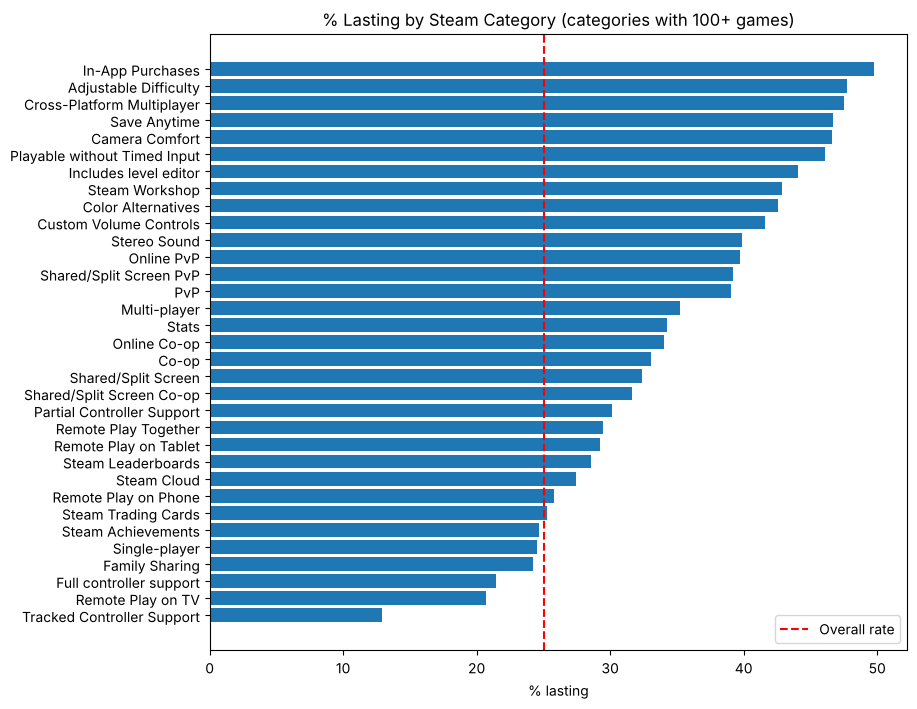

In [11]:
cat_stats = (explore[["categories", "lasting"]].explode("categories")
             .groupby("categories")["lasting"].agg(["mean", "count"])
             .query("count >= 100").sort_values("mean"))

plt.figure(figsize=(9, 8))
plt.barh(cat_stats.index, cat_stats["mean"] * 100)
plt.axvline(explore["lasting"].mean() * 100, color="red", linestyle="--", label="Overall rate")
plt.title("% Lasting by Steam Category (categories with 100+ games)")
plt.xlabel("% lasting")
plt.legend()
plt.show()

**Insight:** online and community features go with staying power:
- **In-App Purchases** about 50%, typical of "live" service games
- **Cross-Platform Multiplayer** about 47%
- **Includes level editor** about 44%
- **Steam Workshop** (original content created by player's) about 43%
- **Online PvP** about 40%

**Single-player** games sit at the average (25%), and **VR controller games** are lowest (13%).

**Red flag confirmed:** the accessibility labels (Adjustable Difficulty, Save Anytime, Camera Comfort, Playable without Timed Input, etc.) are lasting 45–48% of the time. That's consistent with them being added by studios still updating their games. They're removed as leakage in Section 4.1.

#### Plot 4: Share of lasting games by regular price

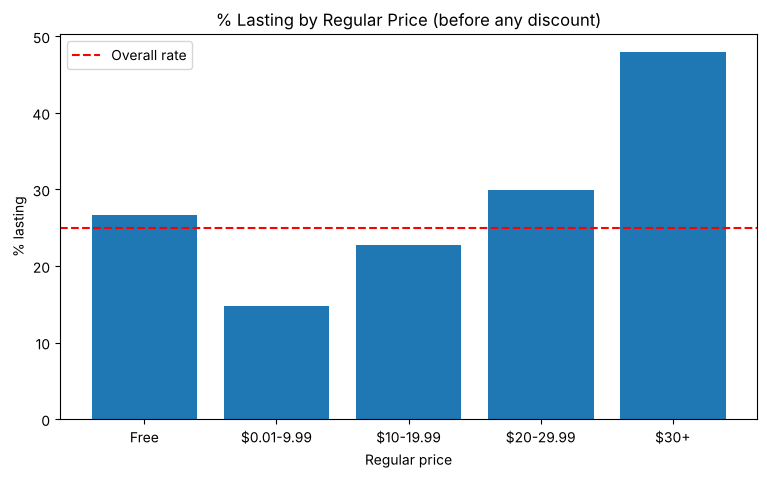

Share of these games on sale on the snapshot day: 66.5 %
Median snapshot price: $ 5.19 | median regular price: $ 14.98


,mean,count
regular_price,,
Free,0.266,428
$0.01-9.99,0.148,920
$10-19.99,0.228,1071
$20-29.99,0.300,494
$30+,0.479,380


In [12]:
price_bands = pd.cut(explore["regular_price"], bins=[-0.01, 0, 9.99, 19.99, 29.99, 10_000],
                     labels=["Free", "$0.01-9.99", "$10-19.99", "$20-29.99", "$30+"])
price_stats = explore.groupby(price_bands, observed=True)["lasting"].agg(["mean", "count"])

plt.figure(figsize=(9, 5))
plt.bar(price_stats.index.astype(str), price_stats["mean"] * 100)
plt.axhline(explore["lasting"].mean() * 100, color="red", linestyle="--", label="Overall rate")
plt.title("% Lasting by Regular Price (before any discount)")
plt.xlabel("Regular price")
plt.ylabel("% lasting")
plt.legend()
plt.show()

print("Share of these games on sale on the snapshot day:", round((explore["discount"] > 0).mean() * 100, 1), "%")
print("Median snapshot price: $", explore["price"].median(), "| median regular price: $",
      round(explore["regular_price"].median(), 2))
price_stats.round(3)

**Insight:**
- **A data surprise:** **2/3 of these games were on sale on the snapshot day.** The median listed price was $5.19, against a median regular price of $14.98. Using the snapshot price would have badly distorted price, so we recover the regular price from the CSV's discount column.
- **Price pattern:** staying power rises with regular price, from **15% for games under $10** to **30% at $20–30** and **48% at $30+**. Free games (27%) do better than cheap paid ones, probably because many of them are online live-service games.
- **To consider: not as a pricing rule but a pattern:** higher prices usually go with bigger, deeper games.

#### Plot 5 -> Sanity check: does our measure just reward bigger hits?

Our target compares each game with others of the same size. If that worked, the share of lasting games should be close to flat across hit sizes. For comparison, the cell also shows the simpler "players per 1,000 reviews" measure we tried first.

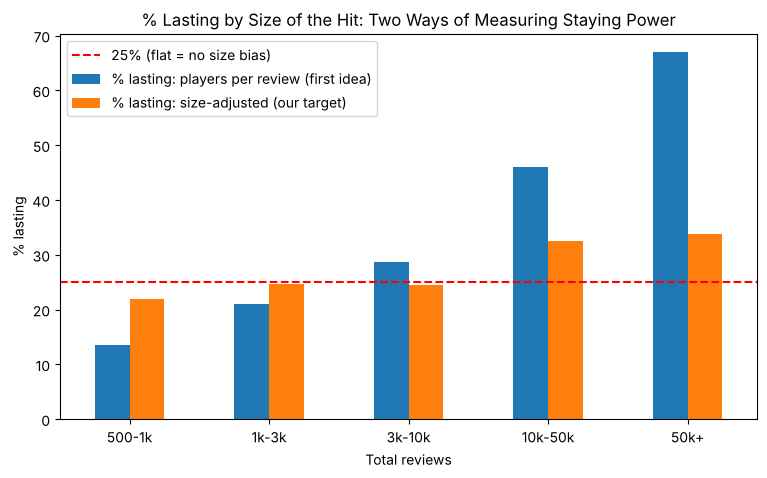

,% lasting: players per review (first idea),% lasting: size-adjusted (our target),games
total_reviews,,,
500-1k,13.5,21.9,987
1k-3k,21.0,24.6,1126
3k-10k,28.7,24.4,672
10k-50k,46.0,32.5,372
50k+,66.9,33.8,136


In [13]:
size_bands = pd.cut(explore["total_reviews"], bins=[499, 1000, 3000, 10_000, 50_000, 10**8],
                    labels=["500-1k", "1k-3k", "3k-10k", "10k-50k", "50k+"])
# The first idea: top 25% of players per 1,000 reviews within each year (no size adjustment)
ratio_cut = explore.groupby("release_year")["players_per_1k"].transform(lambda s: s.quantile(LASTING_QUANTILE))
explore["lasting_ratio_version"] = (explore["players_per_1k"] > ratio_cut).astype(int)

size_stats = pd.DataFrame({
    "% lasting: players per review (first idea)": explore.groupby(size_bands, observed=True)["lasting_ratio_version"].mean() * 100,
    "% lasting: size-adjusted (our target)": explore.groupby(size_bands, observed=True)["lasting"].mean() * 100,
    "games": explore.groupby(size_bands, observed=True).size(),
})

size_stats.iloc[:, :2].plot.bar(figsize=(9, 5), rot=0)
plt.axhline(25, color="red", linestyle="--", label="25% (flat = no size bias)")
plt.title("% Lasting by Size of the Hit: Two Ways of Measuring Staying Power")
plt.xlabel("Total reviews")
plt.ylabel("% lasting")
plt.legend()
plt.show()
size_stats.round(1)

**Insight:** this check is why we changed our target.
- **Our first idea was biased toward big hits.** With "players per 1,000 reviews", the share of lasting games climbed from **13.5% for the smallest hits to 67% for the biggest**.
- **The size-adjusted target is much flatter** (22–34%), so it mostly measures staying power rather than size.
- A small upward tilt remains for the largest games. With only 136 games above 50k reviews, part of that is noise.

### 3.3 Correlations

We use **Spearman** correlation, based on ranks because most variables are heavily skewed.

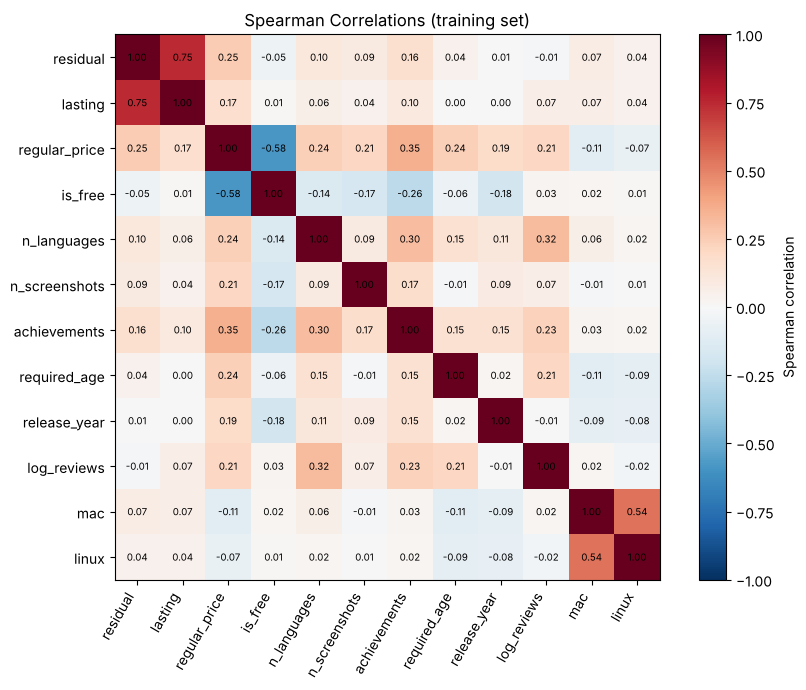

regular_price    0.254
achievements     0.163
n_languages      0.102
n_screenshots    0.091
mac              0.074
linux            0.042
required_age     0.041
release_year     0.006
log_reviews     -0.010
is_free         -0.049
Name: residual, dtype: float64

In [14]:
corr_cols = ["residual", "lasting", "regular_price", "is_free", "n_languages", "n_screenshots",
             "achievements", "required_age", "release_year", "log_reviews", "mac", "linux"]
corr = explore[corr_cols].astype(float).corr(method="spearman")

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)), corr_cols, rotation=60, ha="right")
ax.set_yticks(range(len(corr_cols)), corr_cols)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(im, label="Spearman correlation")
plt.title("Spearman Correlations (training set)")
plt.tight_layout()
plt.show()

corr["residual"].drop(["residual", "lasting"]).sort_values(ascending=False).round(3)

**Insight:** we correlate the features with the **residual** (players above or below expectation):
- **Size and release year:** almost zero correlation with the residual (−0.01 and +0.01). That confirms the target design sucessfully removed both effects.
- **Strongest single numeric signals:** regular price (+0.25) and achievements (+0.16).
- **Weak signals:** languages and screenshots (+0.10 and +0.09) are much weaker here than for popularity.

All of these are modest, which suggests the **categorical features** (genres and categories, which aren't in this matrix) will carry much of the signal.

### 3.4 Transformations

**Promising transformations**
- Recover the **regular price** from the snapshot price and discount.
- `log(1 + x)` for skewed counts (price, achievements, languages, description lengths).
- Multi-hot encoding of genres and categories.
- A **count of social or online features** (multiplayer, co-op, PvP, Workshop, ...).
- Developer and publisher history.

**Extra data that would help** (not in this dataset)
- **Player counts over time:** monthly averages instead of one day, e.g. from SteamDB or SteamCharts. This would remove most of the single-day noise.
- **Post-launch update history:** patch frequency, content roadmaps, DLC release dates. These are the levers studios actually use to keep players.
- **Community size:** Discord members, subreddit size, Workshop item counts, esports scene.
- **Launch-day store snapshots,** to confirm which features existed at launch (e.g. from the Wayback Machine.com).

**What we learned from data exploration**
1. Staying power must be measured relative to **size and age**: bigger hits keep proportionally more players, and newer games have had less time to lose them.
2. **Genre** is the strongest signal: replayable genres (sports, strategy, MMO, simulation) last; finishable ones (action, adventure) don't.
3. **Online and community features** (multiplayer, Workshop, level editors, in-app purchases) go with lasting games.
4. **Higher-priced, deeper games** last longer. The snapshot price was distorted by sales and had to be corrected.
5. Some store labels (accessibility options) are added *because* a game is still supported, so they're leakage.

## 4. Prepare the Data

### 4.1 Leakage audit

A feature is only allowed if it would be known **on launch day**. Anything measured after launch, or that a game only gets *because* players stayed, would let the model "cheat". We drop:

| Column(s) | Why it leaks |
|---|---|
| peak_ccu, positive, negative (total reviews), and the derived residual / expected players | They define the target |
| recommendations, estimated_owners | Outcomes that grow with the player base |
| average/median playtime (forever and 2 weeks) | Measured from players after launch; long playtime *is* staying power |
| metacritic_score, metacritic_url, user_score, score_rank, reviews | Post-launch ratings and press |
| dlc_count | DLC is usually released *because* players stayed |
| tags (parquet and CSV) | Applied by players after launch (used only as a filter) |
| discount | Whether a game was on sale on the snapshot day (only used to recover the regular price) |

**Leaky values inside `categories`.** Some categories are added to store pages long after launch, and mostly by studios still actively supporting a game, which is exactly what we're predicting:
- **Steam Trading Cards** (and SteamVR Collectibles): Valve generally grants them after a game has sold well.
- **Accessibility and audio labels** ("Adjustable Text Size", "Subtitle Options", "Color Alternatives", "Surround Sound", "Save Anytime", ...) and **"Steam Timeline"**: our understanding is that Steam only added these labels around 2024 (TODO: confirm with a source). A 2019–2023 game showing them means the studio was still updating its store page years later.

**Grey areas we keep, but flag as limitations:**
- **Categories like Steam Workshop or Online Co-op** can be added in post-launch updates. They usually describe the game's design, so we keep them.
- **Supported languages** can grow after launch.

In [15]:
LEAKAGE_COLS = ["peak_ccu", "positive", "negative", "total_reviews", "players_per_1k", "residual",
                "expected_players", "recommendations",
                "estimated_owners", "average_playtime_forever", "average_playtime_2weeks",
                "median_playtime_forever", "median_playtime_2weeks", "metacritic_score", "metacritic_url",
                "user_score", "score_rank", "reviews", "dlc_count", "tags", "tags_csv", "discount"]

LEAKY_CATEGORIES = {
    "Steam Trading Cards", "SteamVR Collectibles", "Steam Timeline",
    "Adjustable Text Size", "Subtitle Options", "Color Alternatives", "Camera Comfort",
    "Custom Volume Controls", "Stereo Sound", "Surround Sound", "Narrated Game Menus",
    "Chat Speech-to-text", "Chat Text-to-speech", "Playable without Timed Input",
    "Keyboard Only Option", "Mouse Only Option", "Touch Only Option", "Adjustable Difficulty",
    "Save Anytime", "HDR available",
}
print(len(LEAKAGE_COLS), "leakage columns will never be used as features;",
      len(LEAKY_CATEGORIES), "category values will be removed.")

22 leakage columns will never be used as features; 20 category values will be removed.


### 4.2 Developer and publisher track record

A studio's experience probably matters. We build it so that it **only uses information from before each game's release**:
- `dev_prior_games` / `pub_prior_games`: how many games the same main developer or publisher released on Steam **before** this game. This uses release dates only, not outcomes.
- `dev_prior_hit` / `pub_prior_hit`: whether the developer or publisher had a game with `HIT_THRESHOLD`+ reviews released **before 2019**. Those games are outside our study window, so their outcomes never appear in our labels.

In [16]:
def first_name(value):
    return str(value[0]) if n_items(value) > 0 else "Unknown"

history = games_all[["appID", "release_dt", "developers", "publishers", "total_reviews"]].copy()
history["main_developer"] = history["developers"].map(first_name)
history["main_publisher"] = history["publishers"].map(first_name)

for who in ["developer", "publisher"]:
    key = f"main_{who}"
    prior = history.groupby(key)["release_dt"].rank(method="min") - 1
    history[f"{who[:3]}_prior_games"] = prior.where(history[key] != "Unknown", 0).fillna(0)

early_hits = history[(history["release_dt"].dt.year < WINDOW_START) & (history["total_reviews"] >= HIT_THRESHOLD)]
hit_devs = set(early_hits["main_developer"]) - {"Unknown"}
hit_pubs = set(early_hits["main_publisher"]) - {"Unknown"}
history["dev_prior_hit"] = history["main_developer"].isin(hit_devs).astype(int)
history["pub_prior_hit"] = history["main_publisher"].isin(hit_pubs).astype(int)

history_features = history.set_index("appID")[
    ["main_publisher", "dev_prior_games", "pub_prior_games", "dev_prior_hit", "pub_prior_hit"]]
print("Developers with a pre-2019 hit:", len(hit_devs), "| publishers:", len(hit_pubs))

Developers with a pre-2019 hit: 2980 | publishers: 2212


### 4.3 Feature engineering

`add_features` creates the model inputs. Each new column is calculated from **one row at a time**, so it's safe to apply to the training and test sets separately. Anything learned from the data (imputation medians, scaling, which publishers and categories are common enough to keep) happens inside the pipeline (Section 4.4), so it's learned from training data only.

| Method (checklist) | Where | Why |
|---|---|---|
| Fix a noisy feature | `regular_price` = snapshot price ÷ (1 − discount) | The snapshot price is distorted by sales |
| Decompose date/time | release date → year, month, weekday | Seasonality and cohort |
| Decompose / aggregate lists | languages, screenshots, genres, categories → counts and multi-hot | Lists can't be used directly |
| Aggregate into new features | `n_social_features` (multiplayer, co-op, PvP, workshop categories); developer/publisher history; self-published | Captures replayability and studio experience |
| Text → numeric | description lengths; sequel flag from the title | Proxy for effort and franchise |
| Transformations | log(1+x) of skewed counts (in pipeline) | Reduces skew for linear and distance-based models |
| Scaling | StandardScaler (in pipeline) | Puts features on the same scale |
| Missing values | median imputation (in pipeline); empty lists → 0 | Keeps all rows |

In [17]:
SEQUEL_PATTERN = re.compile(
    r"(?<![\w.])(?:[2-9]|1[0-9]|II|III|IV|V|VI|VII|VIII|IX|X|XI|XII)(?![\w.+])"
    r"|\b(?:Remastered|Remake|Sequel)\b")

SOCIAL_CATEGORIES = {"Multi-player", "Online Co-op", "Co-op", "Online PvP", "PvP", "Cross-Platform Multiplayer",
                     "Shared/Split Screen", "Shared/Split Screen Co-op", "Shared/Split Screen PvP", "LAN Co-op",
                     "LAN PvP", "MMO", "Remote Play Together", "Steam Workshop", "Includes level editor"}

def to_list(value):
    if value is None or (isinstance(value, float) and np.isnan(value)):
        return []
    if isinstance(value, str):
        return [v.strip(" '\"[]") for v in value.split(",") if v.strip(" '\"[]")]
    return [str(v) for v in value]

def add_features(df):
    out = pd.DataFrame(index=df.index)
    # Business and content
    discount = df["discount"].fillna(0)
    out["regular_price"] = np.where(discount.between(1, 99), df["price"] / (1 - discount / 100), df["price"]).round(2)
    out["is_free"] = (df["price"] == 0).astype(int)
    out["required_age"] = df["required_age"]
    out["achievements"] = df["achievements"]
    out["n_languages"] = df["supported_languages"].map(n_items)
    out["n_audio_languages"] = df["full_audio_languages"].map(n_items)
    out["n_screenshots"] = df["screenshots"].map(n_items)
    out["short_desc_len"] = df["short_description"].fillna("").str.len()
    out["detailed_desc_len"] = df["detailed_description"].fillna("").str.len()
    out["has_website"] = (df["website"].fillna("").str.strip() != "").astype(int)
    out["has_content_notes"] = (df["notes"].fillna("").str.strip() != "").astype(int)
    out["is_sequel"] = df["name"].fillna("").map(lambda s: int(bool(SEQUEL_PATTERN.search(s))))
    out["mac"] = df["mac"].astype(int)
    out["linux"] = df["linux"].astype(int)
    # Release timing
    out["release_year"] = df["release_dt"].dt.year
    out["release_month"] = df["release_dt"].dt.month.astype(str)
    out["release_weekday"] = df["release_dt"].dt.day_name()
    # Lists for multi-hot encoding (leaky category values removed)
    out["genres"] = df["genres"].map(to_list)
    out["categories"] = df["categories"].map(lambda v: [c for c in to_list(v) if c not in LEAKY_CATEGORIES])
    out["n_genres"] = out["genres"].map(len)
    out["n_categories"] = out["categories"].map(len)
    out["n_social_features"] = out["categories"].map(lambda c: len(set(c) & SOCIAL_CATEGORIES))
    # Developer / publisher history (Section 4.2)
    hist = history_features.reindex(df["appID"]).set_index(df.index)
    out = pd.concat([out, hist], axis=1)
    out["self_published"] = (df["developers"].map(first_name) == df["publishers"].map(first_name)).astype(int)
    return out

X_train = add_features(train_set)
y_train = train_set["lasting"].values
X_test = add_features(test_set)
y_test = test_set["lasting"].values

print("Feature table:", X_train.shape)
X_train.head(3)

Feature table: (3293, 28)


,regular_price,is_free,required_age,achievements,n_languages,n_audio_languages,n_screenshots,short_desc_len,detailed_desc_len,has_website,has_content_notes,is_sequel,mac,linux,release_year,release_month,release_weekday,genres,categories,n_genres,n_categories,n_social_features,main_publisher,dev_prior_games,pub_prior_games,dev_prior_hit,pub_prior_hit,self_published
47226,0.00,1,0,7,1,1,10,70,1531,0,0,0,0,0,2019,11,Friday,"[Adventure, Casual, Indie, Free To Play]","[Single-player, Steam Achievements]",4,2,0,Michael Rfdshir,0.0,0.0,0,0,1
94216,14.97,0,0,99,13,13,11,227,3760,1,0,0,1,0,2021,10,Wednesday,"[Simulation, Strategy]","[Single-player, Multi-player, PvP, Online PvP,...",2,14,8,Hooded Horse,1.0,2.0,1,1,0
90142,14.99,0,0,18,18,0,12,240,1056,1,0,0,1,1,2019,3,Wednesday,[Indie],"[Single-player, Steam Achievements, Partial Co...",1,8,0,Hempuli Oy,0.0,1.0,0,1,1


### 4.4 Preprocessing pipeline

- **Skewed numeric columns:** median imputation → `log(1+x)` → standardisation.
- **Other numeric columns:** median imputation → standardisation.
- **0/1 flags:** passed through unchanged.
- **Release month and weekday:** one-hot encoded.
- **Main publisher:** one-hot for the most common publishers; all others grouped into one "less common publisher" column.
- **Genres and categories:** a small custom `MultiHotEncoder` makes one 0/1 column per value that appears in at least 1% of training games.

Everything is in one `ColumnTransformer`, fitted on training data only. Its settings are exposed as parameters so they can be **tuned as hyperparameters** in Section 6.

In [18]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer


class MultiHotEncoder(BaseEstimator, TransformerMixin):
    # One 0/1 column per list value that appears in at least `min_freq` of the training rows

    def __init__(self, min_freq=0.01):
        self.min_freq = min_freq

    def fit(self, X, y=None):
        column = X.iloc[:, 0]
        self.name_ = X.columns[0]
        counts = Counter(item for items in column for item in items)
        self.classes_ = sorted(k for k, v in counts.items() if v / len(column) >= self.min_freq)
        return self

    def transform(self, X):
        position = {c: i for i, c in enumerate(self.classes_)}
        out = np.zeros((len(X), len(self.classes_)))
        for row, items in enumerate(X.iloc[:, 0]):
            for item in items:
                if item in position:
                    out[row, position[item]] = 1
        return out

    def get_feature_names_out(self, input_features=None):
        return np.array([f"{self.name_}={c}" for c in self.classes_], dtype=object)


NUM_LOG = ["regular_price", "achievements", "n_languages", "n_audio_languages", "n_screenshots",
           "short_desc_len", "detailed_desc_len", "dev_prior_games", "pub_prior_games",
           "n_genres", "n_categories", "n_social_features"]
NUM_PLAIN = ["release_year", "required_age"]
FLAGS = ["is_free", "has_website", "has_content_notes", "is_sequel", "mac", "linux",
         "dev_prior_hit", "pub_prior_hit", "self_published"]
CATEGORICAL = ["release_month", "release_weekday"]
PUBLISHER = ["main_publisher"]
MULTI = ["genres", "categories"]
ALL_FEATURES = NUM_LOG + NUM_PLAIN + FLAGS + CATEGORICAL + PUBLISHER + MULTI


def build_preprocessor(features=ALL_FEATURES):
    keep = lambda cols: [c for c in cols if c in features]
    num_log = Pipeline([("impute", SimpleImputer(strategy="median")),
                        ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                        ("scale", StandardScaler())])
    num_plain = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
    parts = [("num_log", num_log, keep(NUM_LOG)),
             ("num_plain", num_plain, keep(NUM_PLAIN)),
             ("flags", "passthrough", keep(FLAGS)),
             ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), keep(CATEGORICAL)),
             ("publisher", OneHotEncoder(handle_unknown="infrequent_if_exist", max_categories=20,
                                         sparse_output=False), keep(PUBLISHER))]
    parts += [(c, MultiHotEncoder(min_freq=0.01), [c]) for c in keep(MULTI)]
    parts = [p for p in parts if len(p[2]) > 0]
    return ColumnTransformer(parts)


preprocessing = build_preprocessor()
X_train_prepared = preprocessing.fit_transform(X_train)
print("Prepared training matrix:", X_train_prepared.shape)

Prepared training matrix: (3293, 105)


## 5. Shortlist Promising Models: Measure and Compare

### 5.1 Quick-and-dirty models from different families

The training set has only about 3,300 games, so we **don't need to sample**: every model is trained on the full training set with (mostly) **default settings** and evaluated with **stratified 5-fold cross-validation**. We report the mean and standard deviation across the folds. Models that support it use `class_weight="balanced"`, so mistakes on the smaller "lasting" class count more.

| Family | Model |
|---|---|
| Baseline | DummyClassifier (always predicts the base rate) |
| Linear | Logistic Regression, Linear SVM |
| Probabilistic | Gaussian Naive Bayes |
| Instance-based | k-Nearest Neighbours |
| Trees | Decision Tree, Random Forest |
| Boosting | Histogram Gradient Boosting |
| Neural net | Multi-layer Perceptron |

In [19]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier

cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
SCORING = {"pr_auc": "average_precision", "roc_auc": "roc_auc", "f1": "f1"}

models = {
    "Dummy (baseline)": DummyClassifier(strategy="prior"),
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Linear SVM": LinearSVC(class_weight="balanced", max_iter=5000),
    "Naive Bayes": GaussianNB(),
    "k-Nearest Neighbours": KNeighborsClassifier(n_neighbors=15),
    "Decision Tree": DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample",
                                            n_jobs=1, random_state=RANDOM_STATE),
    "Gradient Boosting": HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_STATE),
    "Neural Net (MLP)": MLPClassifier(hidden_layer_sizes=(64,), early_stopping=True, max_iter=300,
                                      random_state=RANDOM_STATE),
}


def compare_models(models, X, y, features=ALL_FEATURES):
    rows = []
    for name, model in models.items():
        pipe = Pipeline([("prep", build_preprocessor(features)), ("model", model)])
        start = time.time()
        scores = cross_validate(pipe, X, y, cv=cv, scoring=SCORING, n_jobs=-1)
        rows.append({"model": name,
                     "PR-AUC mean": scores["test_pr_auc"].mean(), "PR-AUC std": scores["test_pr_auc"].std(),
                     "ROC-AUC mean": scores["test_roc_auc"].mean(), "ROC-AUC std": scores["test_roc_auc"].std(),
                     "F1 mean": scores["test_f1"].mean(), "F1 std": scores["test_f1"].std(),
                     "seconds": round(time.time() - start)})
    return pd.DataFrame(rows).set_index("model").sort_values("PR-AUC mean", ascending=False).round(3)


results = compare_models(models, X_train, y_train)
results

,PR-AUC mean,PR-AUC std,ROC-AUC mean,ROC-AUC std,F1 mean,F1 std,seconds
model,,,,,,,
Random Forest,0.588,0.039,0.797,0.016,0.341,0.035,3
Logistic Regression,0.565,0.027,0.785,0.005,0.552,0.015,0
Gradient Boosting,0.562,0.022,0.782,0.013,0.529,0.020,2
Linear SVM,0.561,0.027,0.783,0.006,0.554,0.016,0
Neural Net (MLP),0.556,0.014,0.783,0.013,0.432,0.055,1
k-Nearest Neighbours,0.474,0.005,0.733,0.005,0.283,0.020,0
Naive Bayes,0.415,0.013,0.706,0.019,0.456,0.041,0
Decision Tree,0.322,0.021,0.611,0.023,0.413,0.037,0
Dummy (baseline),0.250,0.001,0.500,0.000,0.000,0.000,2


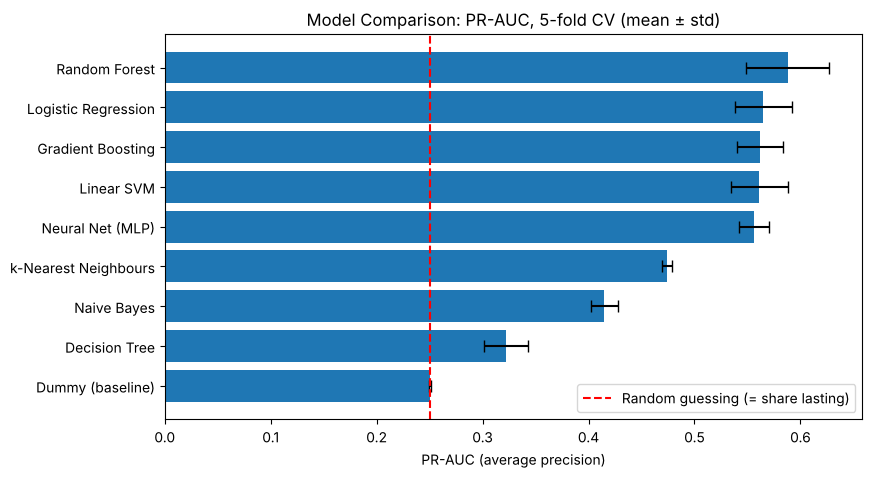

In [20]:
plt.figure(figsize=(9, 5))
order = results.sort_values("PR-AUC mean")
plt.barh(order.index, order["PR-AUC mean"], xerr=order["PR-AUC std"], capsize=4)
plt.axvline(y_train.mean(), color="red", linestyle="--", label="Random guessing (= share lasting)")
plt.title(f"Model Comparison: PR-AUC, {CV_FOLDS}-fold CV (mean ± std)")
plt.xlabel("PR-AUC (average precision)")
plt.legend()
plt.show()

**Interpretation:**
- **Random forest is best** (PR-AUC **0.588 ± 0.039**), followed by **logistic regression (0.565)**, **gradient boosting (0.562)**, **linear SVM (0.561)** and the **neural net (0.556)**. All are well above random guessing (0.25), with a ROC-AUC of about 0.78–0.80.
- The top five are within about one standard deviation of each other, so the ranking between them isn't certain.
- **k-NN (0.47)**, **Naive Bayes (0.42)** and especially a **single decision tree (0.32)** are clearly worse.
- **This is a harder problem than predicting popularity.** Whether a game keeps its players depends heavily on things that happen *after* launch (updates, community, competition), which no launch-day feature can capture.

### 5.2 Most significant variables for each algorithm

- **Logistic regression:** the coefficients (on standardised features) show the direction and strength of each feature's effect.
- **Random forest and gradient boosting:** **permutation importance**. We shuffle one original input column at a time on held-out games and measure how much PR-AUC drops. It scores each *original* feature (for example all of `categories` at once), not each one-hot column.

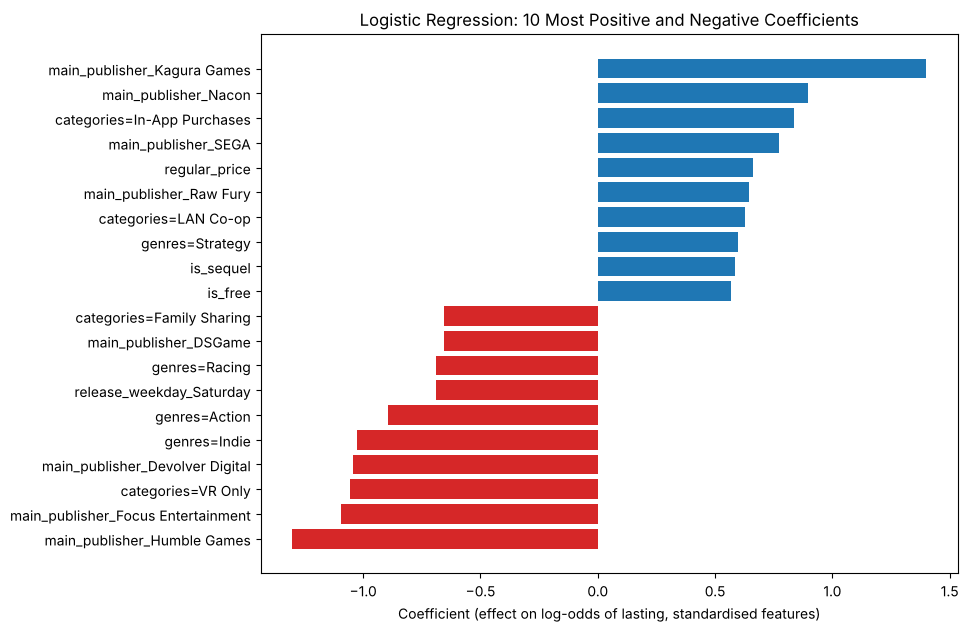

In [21]:
from sklearn.inspection import permutation_importance

# Hold out 25% of the training set to measure importance on games the models didn't train on
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.25,
                                              stratify=y_train, random_state=RANDOM_STATE)

logreg = Pipeline([("prep", build_preprocessor()), ("model", models["Logistic Regression"])]).fit(X_fit, y_fit)
coefs = pd.Series(logreg["model"].coef_[0], index=logreg["prep"].get_feature_names_out())
coefs.index = (coefs.index.str.replace(r"^[a-z_]+__", "", regex=True)
               .str.replace("infrequent_sklearn", "(any less common publisher)"))
top_coefs = pd.concat([coefs.nlargest(10), coefs.nsmallest(10)]).sort_values()

plt.figure(figsize=(9, 7))
plt.barh(top_coefs.index, top_coefs.values, color=np.where(top_coefs.values > 0, "tab:blue", "tab:red"))
plt.title("Logistic Regression: 10 Most Positive and Negative Coefficients")
plt.xlabel("Coefficient (effect on log-odds of lasting, standardised features)")
plt.show()

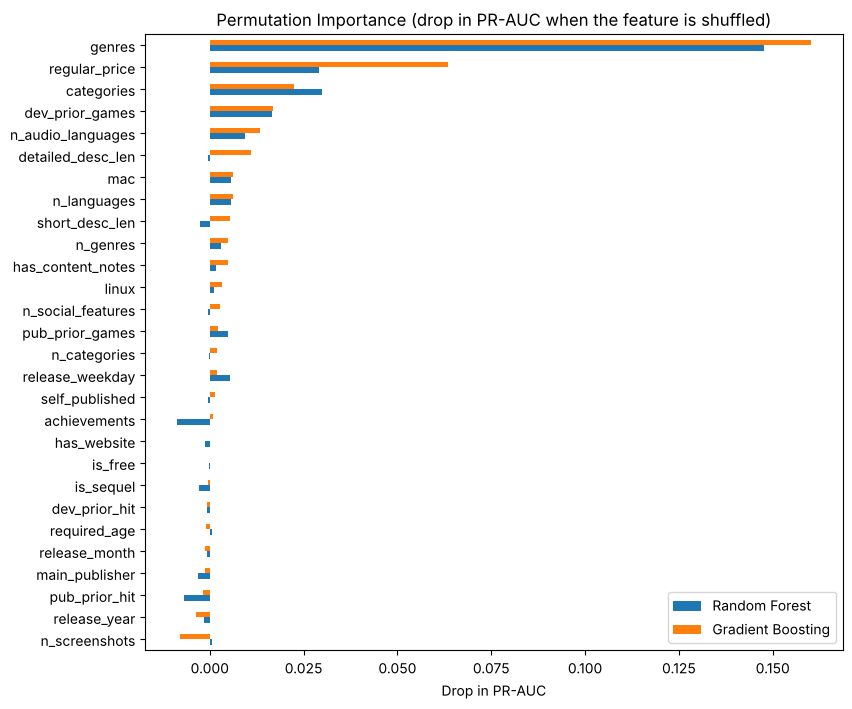

,Random Forest,Gradient Boosting
genres,0.1476,0.1602
regular_price,0.0290,0.0634
categories,0.0300,0.0225
dev_prior_games,0.0166,0.0170
n_audio_languages,0.0095,0.0133
detailed_desc_len,-0.0004,0.0111
mac,0.0056,0.0061
n_languages,0.0057,0.0061
short_desc_len,-0.0027,0.0054
n_genres,0.0031,0.0050


In [22]:
def grouped_importance(name):
    pipe = Pipeline([("prep", build_preprocessor()), ("model", models[name])]).fit(X_fit, y_fit)
    result = permutation_importance(pipe, X_val, y_val, scoring="average_precision",
                                    n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
    return pd.Series(result.importances_mean, index=X_val.columns)

importance = pd.DataFrame({name: grouped_importance(name) for name in ["Random Forest", "Gradient Boosting"]})
importance = importance.sort_values("Gradient Boosting")

importance.plot.barh(figsize=(9, 8))
plt.title("Permutation Importance (drop in PR-AUC when the feature is shuffled)")
plt.xlabel("Drop in PR-AUC")
plt.show()
importance.sort_values("Gradient Boosting", ascending=False).round(4)

**Interpretation:**
- **Genres are by far the most important feature for both tree models** (a PR-AUC drop of about 0.15–0.16 when shuffled). Then come regular price, categories, the developer's number of previous games, and voiced languages.
- **Features that matter little or not at all:** release year (as designed, since our target already adjusts for it), the developer or publisher having a pre-2019 hit, the sequel flag, free-to-play, and the specific publisher.
- **Logistic regression adds direction:**
  - *Positive:* Strategy, LAN Co-op, In-App Purchases, sequels and a higher regular price.
  - *Negative:* Action, Indie, Racing and VR-only.
  - *Publishers:* Devolver Digital, Humble Games and Focus Entertainment have *negative* coefficients. These publishers are known for narrative, finishable indie games, which fits the genre story. Single-publisher coefficients rest on few games, so we don't over-interpret them.

### 5.3 What kinds of errors do the models make?

We take the best model's cross-validated predictions (each game is predicted by a model that didn't see it), pick the threshold that maximises F1, and look at:
- **False negatives:** games that kept their players although the model gave them a low probability.
- **False positives:** games the model was confident about that lost their players.

Model: Random Forest | threshold that maximises F1: 0.29


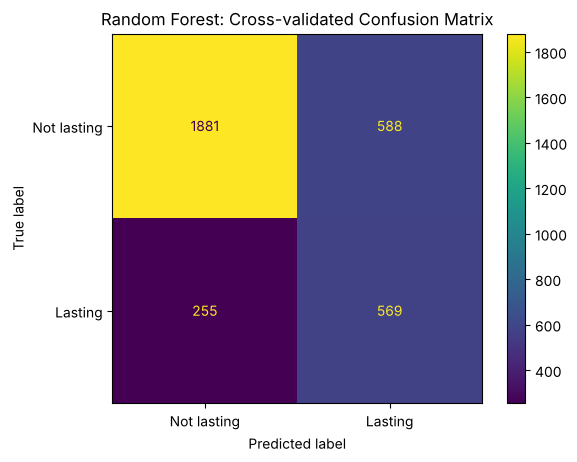

In [23]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve, ConfusionMatrixDisplay

best_name = results.index[0]
best_pipe = Pipeline([("prep", build_preprocessor()), ("model", models[best_name])])
proba = cross_val_predict(best_pipe, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]

precision, recall, thresholds = precision_recall_curve(y_train, proba)
f1_scores = 2 * precision * recall / (precision + recall + 1e-12)
best_threshold = thresholds[np.argmax(f1_scores[:-1])]
predicted = (proba >= best_threshold).astype(int)
print(f"Model: {best_name} | threshold that maximises F1: {best_threshold:.2f}")

ConfusionMatrixDisplay.from_predictions(y_train, predicted, display_labels=["Not lasting", "Lasting"])
plt.title(f"{best_name}: Cross-validated Confusion Matrix")
plt.show()

In [ ]:
errors = train_set[["name", "release_year", "genres", "total_reviews", "peak_ccu", "expected_players"]].copy()
errors["regular_price"] = X_train["regular_price"]
errors["genres"] = errors["genres"].map(lambda g: ", ".join(to_list(g)[:3]))
errors["predicted probability"] = proba.round(3)
errors["actual"] = y_train
errors["predicted"] = predicted

false_negatives = errors[(errors["actual"] == 1) & (errors["predicted"] == 0)]
false_positives = errors[(errors["actual"] == 0) & (errors["predicted"] == 1)]

print("False negatives: lasting games incorrectly predicted as not lasting (lowest probability first)")
display(false_negatives.nsmallest(10, "predicted probability"))
print("False positives: non-lasting games incorrectly predicted as lasting (highest probability first)")
display(false_positives.nlargest(10, "predicted probability"))

In [25]:
# How do the four outcome groups differ? Median of key features
groups = np.select([(y_train == 1) & (predicted == 1), (y_train == 1) & (predicted == 0),
                    (y_train == 0) & (predicted == 1), (y_train == 0) & (predicted == 0)],
                   ["True positive", "False negative", "False positive", "True negative"], default="")
compare_cols = ["regular_price", "n_social_features", "achievements", "n_languages", "n_screenshots",
                "dev_prior_games", "pub_prior_hit", "is_free"]
summary = X_train[compare_cols].groupby(groups).median()
summary["share early access"] = X_train["genres"].map(lambda g: "Early Access" in g).groupby(groups).mean().round(2)
summary.round(1)

,regular_price,n_social_features,achievements,n_languages,n_screenshots,dev_prior_games,pub_prior_hit,is_free,share early access
False negative,15.0,0.0,30.0,8.0,10.0,0.0,0.0,0.0,0.1
False positive,20.0,3.0,39.0,9.0,11.0,1.0,1.0,0.0,0.1
True negative,11.0,0.0,23.0,7.0,10.0,0.0,0.0,0.0,0.1
True positive,20.0,3.0,36.0,9.0,10.0,2.0,1.0,0.0,0.1


**Interpretation** (random forest, threshold 0.29):

- **False negatives (missed lasting games)** are mostly **small hits with only a handful of players** (e.g. 7 players when about 3 were expected), plus a few surprises.
  - With such small numbers, one day's count is noisy, so some of these "lasting" labels are partly luck.
  - The biggest real miss is ***SurrounDead***, an early-access survival game with **1,870 players against about 70 expected**. A strong, continuing community is invisible in launch-day data.
- **False positives** are mostly **strategy, simulation and sports games from established publishers** that the genre pattern says should last, but didn't:
  - *HUMANKIND*, *Stronghold: Warlords* and *Dune: Spice Wars* were well-known launches whose player bases faded.
  - ***MotoGP 21*** is a yearly sports title, which loses its players as soon as next year's edition is released.
- **The typical profile:** missed games look like average single-player games (median 0 social features, no previous releases). False positives look like typical lasting games (3 social features, an established studio).

**What data would a human have used to avoid these errors?**
- **Whether the franchise releases a new edition every year,** which replaces last year's game.
- **Reception after launch:** review scores and the share of negative reviews in the first weeks, plus how the community reacted to updates.
- **The studio's update roadmap:** whether it planned years of content and kept delivering it.
- **Community signals:** Discord size, streamers, mods and Workshop activity.

### 5.4 Iterating: feature selection

We drop the original features whose permutation importance was **zero or negative for both** tree models, re-run the comparison for the strongest model families, and keep the reduced set only if it scores better on average. This is an exploratory feature-selection comparison: because the importance scores and cross-validation comparison use the same training data, the reported CV scores should not be treated as an unbiased estimate of the feature-selection procedure. TODO: the team can add another iteration here.

In [26]:
weak = importance.index[(importance["Gradient Boosting"] <= 0) & (importance["Random Forest"] <= 0)].tolist()
FEATURES_V2 = [f for f in ALL_FEATURES if f not in weak]
print("Candidate features to drop:", weak if weak else "none")

top_names = [n for n in results.index if n != "Dummy (baseline)"][:4]
results_v2 = compare_models({n: models[n] for n in top_names}, X_train, y_train, features=FEATURES_V2)

comparison = results.loc[top_names, ["PR-AUC mean", "PR-AUC std"]].join(
    results_v2[["PR-AUC mean", "PR-AUC std"]], rsuffix=" (v2)")
if comparison["PR-AUC mean (v2)"].mean() < comparison["PR-AUC mean"].mean():
    FEATURES_V2 = ALL_FEATURES
    print("The reduced set didn't help, so we keep all features.")
print("Features used from here on:", len(FEATURES_V2))
comparison

Candidate features to drop: ['release_year', 'pub_prior_hit', 'main_publisher', 'release_month', 'dev_prior_hit', 'is_sequel', 'is_free']


Features used from here on: 21


,PR-AUC mean,PR-AUC std,PR-AUC mean (v2),PR-AUC std (v2)
model,,,,
Random Forest,0.588,0.039,0.597,0.041
Logistic Regression,0.565,0.027,0.562,0.016
Gradient Boosting,0.562,0.022,0.563,0.030
Linear SVM,0.561,0.027,0.560,0.015


**Interpretation:** seven features had zero or negative importance for both tree models and were dropped:
- release year
- the developer and publisher pre-2019 hit flags
- main publisher and release month
- the sequel flag
- free-to-play

On average the reduced set scored the same or slightly better (random forest 0.588 → 0.597; the others unchanged within noise), so we keep it. Losing **release year** is a good sign: our target already adjusts for age, so the year shouldn't carry information.

TODO (another iteration the team could try): add text features from descriptions (e.g. words like "roguelike", "sandbox", "story", "multiplayer"), or a "yearly sports franchise" flag suggested by the error analysis.

### 5.5 Shortlist

We take forward three models from **different families**, because ensembles work best when their members make different kinds of errors:
1. **Random Forest** (CV PR-AUC 0.588): the best model; bagged trees capture interactions like "strategy *and* multiplayer".
2. **Gradient Boosting** (0.562): a different way of combining trees (boosting), and usually the strongest after tuning.
3. **Logistic Regression** (0.565): a linear, interpretable model with a very different error pattern.

The **linear SVM** (0.561) is another linear model with nearly identical results to logistic regression, so it adds little. The **neural net** (0.556) is slower to tune and harder to explain for a similar score.

## 6. Fine-Tune the System

### 6.1 Hyperparameter tuning with randomized search

We tune each shortlisted model with **`RandomizedSearchCV`** (5-fold CV, PR-AUC, `N_ITER` combinations each) on the **full training set**. Random search is preferred over grid search because each model has several hyperparameters with wide ranges, and random search tries many more distinct values for the same number of fits, as the checklist recommends.

Following the checklist, some **data-preparation choices are tuned as hyperparameters** too:
- whether to apply the log transform
- mean vs. median imputation
- how many publishers keep their own column
- the minimum frequency for a genre or category to get its own column

In [27]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform, randint

prep_space = {
    "prep__num_log__log": [FunctionTransformer(np.log1p, feature_names_out="one-to-one"), "passthrough"],
    "prep__num_log__impute__strategy": ["median", "mean"],
}
if "main_publisher" in FEATURES_V2:
    prep_space["prep__publisher__max_categories"] = [5, 10, 20]
for col in ["genres", "categories"]:
    if col in FEATURES_V2:
        prep_space[f"prep__{col}__min_freq"] = [0.01, 0.02, 0.05]

search_spaces = {
    "Gradient Boosting": (HistGradientBoostingClassifier(random_state=RANDOM_STATE), {
        "model__learning_rate": loguniform(0.01, 0.2),
        "model__max_iter": randint(50, 400),
        "model__max_leaf_nodes": randint(7, 40),
        "model__min_samples_leaf": randint(10, 80),
        "model__l2_regularization": loguniform(1e-3, 10),
        "model__class_weight": [None, "balanced"],
    }),
    "Random Forest": (RandomForestClassifier(n_jobs=1, random_state=RANDOM_STATE), {
        "model__n_estimators": randint(150, 400),
        "model__max_depth": [None, 6, 10, 20],
        "model__min_samples_leaf": randint(1, 15),
        "model__max_features": ["sqrt", 0.3, 0.5],
        "model__class_weight": [None, "balanced_subsample"],
    }),
    "Logistic Regression": (LogisticRegression(max_iter=3000), {
        "model__C": loguniform(1e-3, 10),
        "model__class_weight": [None, "balanced"],
    }),
}

tuned, best_params, tuning_rows = {}, {}, []
for name, (model, space) in search_spaces.items():
    pipe = Pipeline([("prep", build_preprocessor(FEATURES_V2)), ("model", model)])
    search = RandomizedSearchCV(pipe, {**prep_space, **space}, n_iter=N_ITER, cv=cv,
                                scoring="average_precision", n_jobs=-1, random_state=RANDOM_STATE)
    start = time.time()
    search.fit(X_train, y_train)
    best = search.best_index_
    tuned[name] = search.best_estimator_
    best_params[name] = search.best_params_
    tuning_rows.append({"model": name,
                        "default PR-AUC (Section 5)": results.loc[name, "PR-AUC mean"],
                        "tuned PR-AUC mean": search.cv_results_["mean_test_score"][best],
                        "tuned PR-AUC std": search.cv_results_["std_test_score"][best],
                        "minutes": round((time.time() - start) / 60, 1)})
    print(f"{name}: best parameters")
    for k, v in search.best_params_.items():
        print(f"    {k} = {v}")

tuning_results = pd.DataFrame(tuning_rows).set_index("model").round(3)
tuning_results

Gradient Boosting: best parameters
    model__class_weight = balanced
    model__l2_regularization = 2.1368329072358767
    model__learning_rate = 0.018891200276189388
    model__max_iter = 241
    model__max_leaf_nodes = 27
    model__min_samples_leaf = 42
    prep__categories__min_freq = 0.02
    prep__genres__min_freq = 0.02
    prep__num_log__impute__strategy = median
    prep__num_log__log = passthrough


Random Forest: best parameters
    model__class_weight = None
    model__max_depth = 20
    model__max_features = sqrt
    model__min_samples_leaf = 2
    model__n_estimators = 260
    prep__categories__min_freq = 0.01
    prep__genres__min_freq = 0.02
    prep__num_log__impute__strategy = median
    prep__num_log__log = passthrough


Logistic Regression: best parameters
    model__C = 0.0340178999112854
    model__class_weight = None
    prep__categories__min_freq = 0.02
    prep__genres__min_freq = 0.05
    prep__num_log__impute__strategy = median
    prep__num_log__log = FunctionTransformer(feature_names_out='one-to-one', func=<ufunc 'log1p'>)


,default PR-AUC (Section 5),tuned PR-AUC mean,tuned PR-AUC std,minutes
model,,,,
Gradient Boosting,0.562,0.591,0.022,0.9
Random Forest,0.588,0.600,0.039,1.7
Logistic Regression,0.565,0.566,0.020,0.1


**Interpretation:** tuning helped the tree models most:
- **Gradient boosting:** 0.562 → **0.591 ± 0.022**
- **Random forest:** 0.588 → **0.600 ± 0.039**
- **Logistic regression:** 0.565 → 0.566 (essentially unchanged)

The preparation choices tuned as hyperparameters make sense: **trees chose no log transform** (they only care about the order of values), while **logistic regression chose the log transform**. Gradient boosting chose a **small learning rate (0.019)** with fairly large leaves, a cautious setting that fits a small, noisy dataset.

### 6.2 Ensembles

We combine the tuned models in two ways and compare them with the best single model, using the same cross-validation:
- **Soft voting:** averages the three models' predicted probabilities.
- **Stacking:** a logistic regression learns how much to trust each model, using their out-of-fold predictions.

In [28]:
from sklearn.ensemble import VotingClassifier, StackingClassifier

estimators = [(name.replace(" ", "_"), model) for name, model in tuned.items()]
ensembles = {
    "Soft voting": VotingClassifier(estimators, voting="soft"),
    "Stacking": StackingClassifier(estimators, final_estimator=LogisticRegression(max_iter=2000),
                                   cv=3, stack_method="predict_proba"),
}

ensemble_rows = []
for name, model in ensembles.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=SCORING, n_jobs=-1)
    ensemble_rows.append({"model": name, "PR-AUC mean": scores["test_pr_auc"].mean(),
                          "PR-AUC std": scores["test_pr_auc"].std()})

final_comparison = pd.concat([
    tuning_results.rename(columns={"tuned PR-AUC mean": "PR-AUC mean", "tuned PR-AUC std": "PR-AUC std"})
                  [["PR-AUC mean", "PR-AUC std"]],
    pd.DataFrame(ensemble_rows).set_index("model"),
]).sort_values("PR-AUC mean", ascending=False).round(3)

final_name = final_comparison.index[0]
final_model = ensembles[final_name] if final_name in ensembles else tuned[final_name]
print("Final model (best cross-validated PR-AUC):", final_name)
final_comparison

Final model (best cross-validated PR-AUC): Soft voting


,PR-AUC mean,PR-AUC std
model,,
Soft voting,0.603,0.025
Stacking,0.603,0.028
Random Forest,0.600,0.039
Gradient Boosting,0.591,0.022
Logistic Regression,0.566,0.020


**Interpretation:** **soft voting and stacking both score 0.603**, just above the tuned random forest (0.600). Soft voting also has a smaller spread across folds (±0.025 vs. ±0.039), so it's the more stable choice. It wins by our rule (best mean CV score), but the gain is within noise. TODO (team decision): the tuned random forest alone would be almost as good and simpler to explain.

### 6.3 Choosing the decision threshold

We choose the threshold that **maximises F1 on cross-validated predictions from the training data**, so the test set plays no part in it. A publisher that cares more about catching every lasting game could choose a lower one (higher recall).

In [29]:
train_proba = cross_val_predict(final_model, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
precision, recall, thresholds = precision_recall_curve(y_train, train_proba)
f1_scores = 2 * precision * recall / (precision + recall + 1e-12)
i = np.argmax(f1_scores[:-1])
THRESHOLD = thresholds[i]
print(f"Chosen threshold: {THRESHOLD:.3f} (CV precision {precision[i]:.2f}, recall {recall[i]:.2f})")

Chosen threshold: 0.360 (CV precision 0.51, recall 0.68)


### 6.4 Final evaluation on the test set

We retrain the final model on the **whole training set** and evaluate it **once** on the test set, against two baselines:
- the **Dummy** model (random guessing at the base rate)
- an **untuned logistic regression**, the simple model a team might have started with

*From here on we don't change the model:* tweaking it after seeing test results would overfit the test set (Géron's warning).

In [30]:
from sklearn.metrics import average_precision_score, roc_auc_score, f1_score, precision_score, recall_score

final_model.fit(X_train, y_train)
baselines = {
    "Dummy (base rate)": Pipeline([("prep", build_preprocessor()), ("model", DummyClassifier(strategy="prior"))]),
    "Logistic Regression (untuned)": Pipeline([("prep", build_preprocessor()),
                                               ("model", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
}
for model in baselines.values():
    model.fit(X_train, y_train)

test_rows, test_probas = [], {}
for name, model in {**baselines, f"FINAL: {final_name}": final_model}.items():
    p = model.predict_proba(X_test)[:, 1]
    test_probas[name] = p
    thr = THRESHOLD if name.startswith("FINAL") else 0.5
    pred = (p >= thr).astype(int)
    test_rows.append({"model": name, "PR-AUC": average_precision_score(y_test, p),
                      "ROC-AUC": roc_auc_score(y_test, p), "F1": f1_score(y_test, pred, zero_division=0),
                      "precision": precision_score(y_test, pred, zero_division=0),
                      "recall": recall_score(y_test, pred, zero_division=0)})
test_results = pd.DataFrame(test_rows).set_index("model").round(3)
test_results

,PR-AUC,ROC-AUC,F1,precision,recall
model,,,,,
Dummy (base rate),0.258,0.500,0.000,0.000,0.000
Logistic Regression (untuned),0.552,0.755,0.545,0.464,0.662
FINAL: Soft voting,0.578,0.768,0.551,0.479,0.648


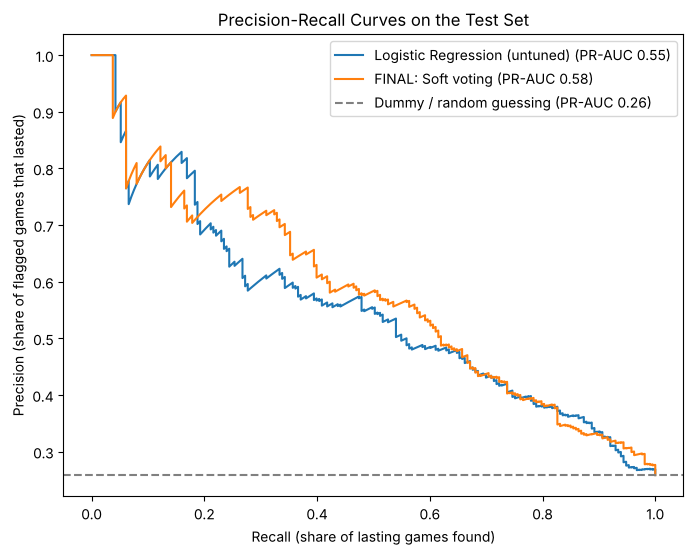

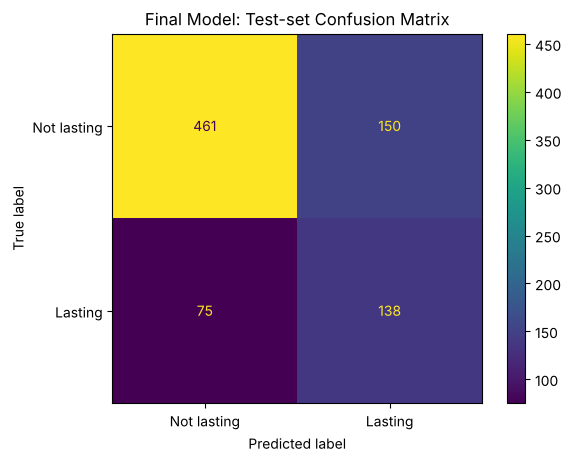

In [31]:
plt.figure(figsize=(8, 6))
for name, p in test_probas.items():
    if name.startswith("Dummy"):
        continue
    prec, rec, _ = precision_recall_curve(y_test, p)
    plt.plot(rec, prec, label=f"{name} (PR-AUC {average_precision_score(y_test, p):.2f})")
plt.axhline(y_test.mean(), color="gray", linestyle="--",
            label=f"Dummy / random guessing (PR-AUC {y_test.mean():.2f})")
plt.title("Precision-Recall Curves on the Test Set")
plt.xlabel("Recall (share of lasting games found)")
plt.ylabel("Precision (share of flagged games that lasted)")
plt.legend()
plt.show()

ConfusionMatrixDisplay.from_predictions(y_test, (test_probas[f"FINAL: {final_name}"] >= THRESHOLD).astype(int),
                                        display_labels=["Not lasting", "Lasting"])
plt.title("Final Model: Test-set Confusion Matrix")
plt.show()

**Interpretation (test set, used once):**

| | PR-AUC | ROC-AUC | Precision | Recall | F1 |
|---|---|---|---|---|---|
| Dummy (random guessing) | 0.258 | 0.50 | n/a | 0 | 0 |
| Logistic regression (untuned) | 0.552 | 0.755 | 0.46 | 0.66 | 0.55 |
| **Final model (soft voting)** | **0.578** | **0.768** | **0.48** | **0.65** | **0.55** |

- **In plain terms:** of the games the model flags as "likely to last", **48% really did**, against **26%** for a random pick (about **1.9× better**). It finds about **two-thirds** of all lasting games.
- **Better than both baselines, but the gap is modest:** the final model beats the untuned logistic regression on PR-AUC (0.578 vs. 0.552) and ROC-AUC, but only by a little. Most of the signal is simple enough for a linear model to find.
- **No sign of overfitting:** the test PR-AUC (0.578) is close to the cross-validated score (0.603).
- **The model is useful but far from perfect.** Staying power depends a lot on what happens after launch.

### 6.5 Explaining the final model: what predicts staying power?

Permutation importance on the test set shows which **original features** the final model relies on most. Partial dependence plots then show *how* the predicted probability changes as one feature changes, with everything else averaged out.

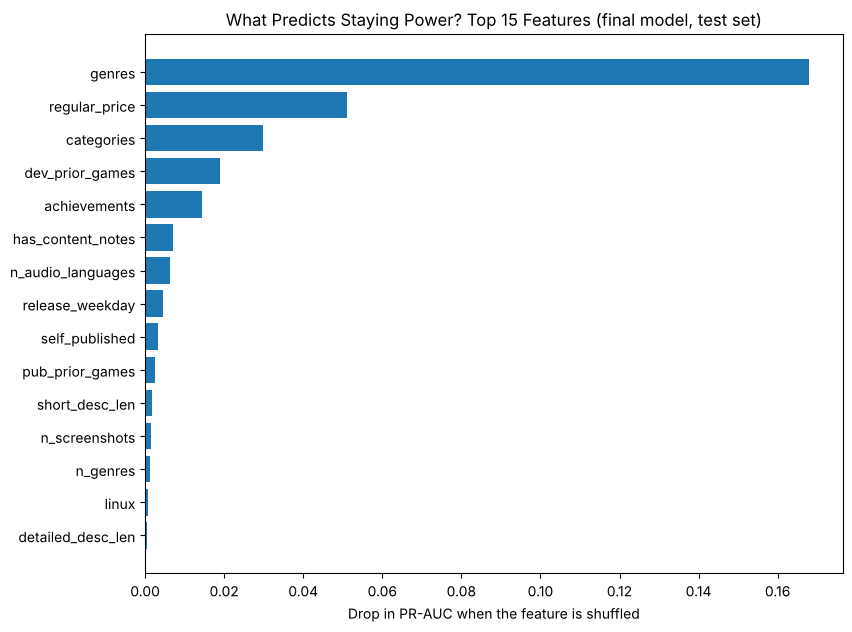

In [32]:
final_importance = permutation_importance(final_model, X_test, y_test, scoring="average_precision",
                                          n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
final_importance = pd.Series(final_importance.importances_mean, index=X_test.columns).sort_values().tail(15)

plt.figure(figsize=(9, 7))
plt.barh(final_importance.index, final_importance.values)
plt.title("What Predicts Staying Power? Top 15 Features (final model, test set)")
plt.xlabel("Drop in PR-AUC when the feature is shuffled")
plt.show()

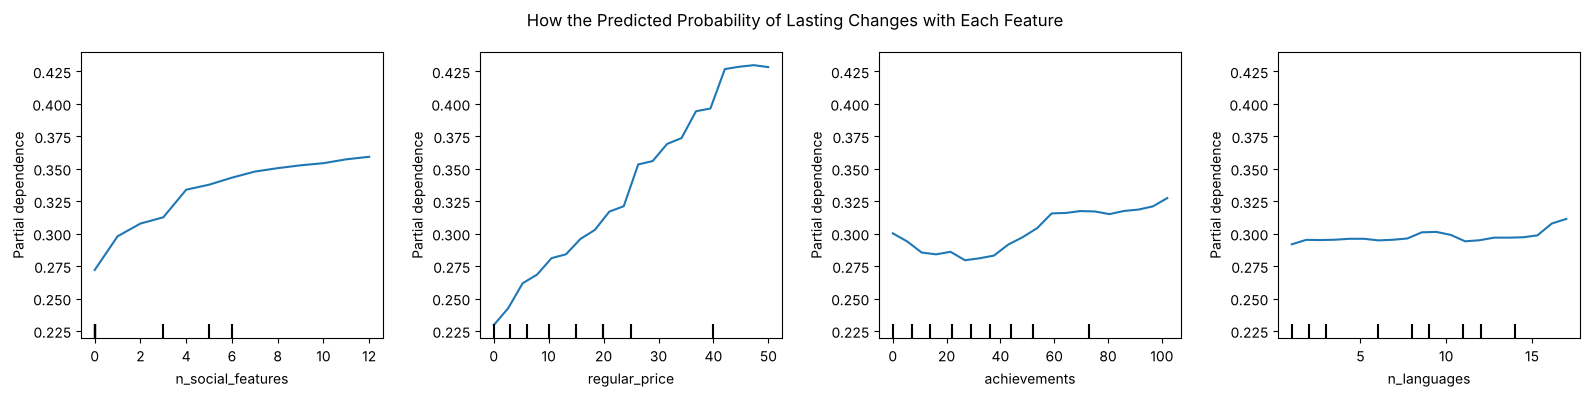

In [33]:
from sklearn.inspection import PartialDependenceDisplay

pdp_features = ["n_social_features", "regular_price", "achievements", "n_languages"]
X_pdp = X_test.astype({f: float for f in pdp_features})   # PDPs need float columns
fig, ax = plt.subplots(1, len(pdp_features), figsize=(16, 4))
PartialDependenceDisplay.from_estimator(final_model, X_pdp, pdp_features, ax=ax,
                                        percentiles=(0.02, 0.95), grid_resolution=20)
fig.suptitle("How the Predicted Probability of Lasting Changes with Each Feature")
plt.tight_layout()
plt.show()

**Takeaways:**
- **"Genre is the number-one predictor of whether a hit keeps its players."** Replayable genres (strategy, simulation, sports, MMO) last; story-driven, finishable genres (action, adventure) fade.
- **Next most important:** regular price, store categories (online, co-op and community features), the developer's experience (number of previous games), and achievements.
- **Social features:** each extra online or community feature raises the predicted probability, from about **27% with none** to about **35% with 5 or more**.
- **Price:** the predicted probability rises from about **23% for free or very cheap games to about 43% at $40+**. Price stands in for the size and depth of the game.
- **Languages barely matter for staying power** (flat curve), unlike for popularity. Languages help a game *reach* players, not *keep* them.

**Correlation, not causation:** adding multiplayer won't by itself make a game last. Lasting games tend to be *designed* around replayable systems and communities, and these features are signs of that design.

### 6.6 Robustness checks

These checks use **cross-validation on the training set only**, so the test set still plays no part in any decision.

1. **Does the model depend on languages?** The number of languages could be a stand-in for budget, or could grow after a game succeeds. We retrain the tuned gradient boosting model without `n_languages` and `n_audio_languages`.
2. **Does the conclusion depend on how we defined "lasting"?** We swap our target for a simpler one, *at least 50 concurrent players on the snapshot day* (no division by reviews, no per-year cutoff), and check whether the same features come out on top.

In [34]:
from sklearn.base import clone

gb_tuned = tuned["Gradient Boosting"]

def cv_pr_auc(model, X, y):
    s = cross_validate(model, X, y, cv=cv, scoring="average_precision", n_jobs=-1)["test_score"]
    return round(s.mean(), 3), round(s.std(), 3)

# 1. Without languages (rebuild the preprocessing without those two columns)
no_lang = [f for f in FEATURES_V2 if f not in ("n_languages", "n_audio_languages")]
gb_no_lang = clone(gb_tuned).set_params(prep=build_preprocessor(no_lang))
gb_no_lang.set_params(**{k: v for k, v in best_params["Gradient Boosting"].items() if k.startswith("prep__")})

# 2. Alternative target: 50+ concurrent players on the snapshot day
y_alt = (train_set["peak_ccu"] >= 50).astype(int).values

robust = pd.DataFrame({
    "check": ["Tuned gradient boosting (main)", "... without language features",
              "... with the alternative target (50+ players)"],
    "share positive": [y_train.mean(), y_train.mean(), y_alt.mean()],
    "CV PR-AUC (mean, std)": [cv_pr_auc(gb_tuned, X_train, y_train), cv_pr_auc(gb_no_lang, X_train, y_train),
                              cv_pr_auc(gb_tuned, X_train, y_alt)],
}).round(3)
robust

,check,share positive,"CV PR-AUC (mean, std)"
0,Tuned gradient boosting (main),0.250,"(0.591, 0.022)"
1,... without language features,0.250,"(0.589, 0.027)"
2,... with the alternative target (50+ players),0.239,"(0.651, 0.017)"


In [35]:
# Do the same features matter for both targets? Same model, same validation split, two different targets
y_alt_series = pd.Series(y_alt, index=X_train.index)

def gb_importance(y_fit_part, y_val_part):
    model = clone(gb_tuned).fit(X_fit, y_fit_part)
    result = permutation_importance(model, X_val, y_val_part, scoring="average_precision",
                                    n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
    return pd.Series(result.importances_mean, index=X_val.columns)

imp_main = gb_importance(y_fit, y_val)
imp_alt = gb_importance(y_alt_series.loc[X_fit.index].values, y_alt_series.loc[X_val.index].values)

top_compare = pd.DataFrame({
    "rank: main target": imp_main.rank(ascending=False).astype(int),
    "rank: 50+ players target": imp_alt.rank(ascending=False).astype(int),
}).sort_values("rank: main target").head(10)
top_compare

,rank: main target,rank: 50+ players target
genres,1,5
regular_price,2,1
categories,3,2
n_audio_languages,4,27
n_social_features,5,26
n_languages,6,3
dev_prior_games,7,11
self_published,8,24
detailed_desc_len,9,28
n_genres,10,23


**Interpretation:**
1. **Removing the language features changes almost nothing** (CV PR-AUC 0.591 → 0.589). Whatever the number of languages stands for (budget, ambition, or translations added after success), the staying-power model doesn't depend on it.
2. **With the simpler target (50+ players on the snapshot day),** the model scores a higher PR-AUC (0.651), and **price, categories, genres and languages are again near the top**. Two differences:
   - **The number of languages jumps to rank 3** for the simple target but is only rank 6 for ours. A raw player count partly measures *size*, and languages track size.
   - **Social features and description length matter much less** for the simple target.

   This supports our size-adjusted definition: it isolates *staying power* rather than *bigness*, while the main conclusions (genre, price, online features) hold either way.

## 7. Conclusion

**Summary.** We studied about 4,100 Steam hits (500+ reviews, released 2019–2023) and predicted which ones still have more players than expected for their size and age, years after launch. After comparing nine model families, tuning three and combining them, our final soft-voting ensemble reaches a **test PR-AUC of 0.58** (random guessing: 0.26) and a **ROC-AUC of 0.77**. **48% of the games it flags as lasting really are**, about 1.9× the base rate, and it finds two-thirds of them.

**Key findings for developers and publishers**
1. **Genre is the strongest predictor of staying power.** Games built around replayable systems (strategy, simulation, sports, MMO, early access) keep their players. Story-driven action and adventure games fade, even when they were hits.
2. **Online and community features matter:** multiplayer, cross-platform play, level editors and Steam Workshop support all go with lasting games.
3. **Deeper, higher-priced games last longer.**
4. **Languages help a game get popular, but not stay popular.** Removing them from this model changed nothing, unlike in a popularity model.
5. **Bigger hits keep proportionally more players** (10× the reviews → about 17× the current players).

**What worked**
- **Defining the target relative to size and age.** Our first idea (players per review) was biased toward big games, and Plot 5 caught it.
- **Correcting the price for sale discounts** using the CSV.
- **Removing leaky store labels.**
- **Tree ensembles**, and **tuning preparation choices** as hyperparameters.

**What didn't work**
- **Naive Bayes, k-NN and single decision trees** were clearly worse.
- **Ensembling and tuning gave only small gains,** and a simple logistic regression came close to the final model. The limit is the information in the data, not the model.

**Assumptions and limitations**

| Assumption / limitation | Likely impact | How it could be addressed |
|---|---|---|
| Peak players on **one single day** measures staying power | Weekends, sales or updates on that day add noise, especially for small games with a handful of players | Use monthly average players (e.g. SteamCharts) or several snapshots |
| Reviews measure the size of the original audience | Genres or regions that review less look like they "kept" more players | Use estimated owners or sales data as the size measure |
| Store features describe the game **at launch** | Workshop support, multiplayer modes or languages added in updates make lasting games look more "social" (reverse causality) | Use archived launch-day store pages |
| Regular price = launch price | Permanent price cuts make some games look cheaper than they launched | Use price-history data (e.g. SteamDB) |
| A fixed definition: top 25% within each year | Games just below the cutoff count as failures | Predict the residual directly with regression, or use several tiers |
| Only games that became hits (500+ reviews) | Results don't apply to small games | A two-stage model: first popularity, then staying power |
| No post-launch data (updates, reception, community) | The biggest driver of staying power is invisible; it caps the model at a modest accuracy | Add patch history, early review scores and community size |
| Idle games removed with player tags | A few idle-style games without those tags may remain | Manual check, or text rules on descriptions |

**Next steps:** replace the one-day player count with an average over time, add post-launch update and review data, and combine this model with a popularity model into a two-stage "will it be a hit, and will it last?" tool.